# Walk on Cylinders (WoC) vs Walk on Heat Balls (WoHB)

Monte Carlo experiments for the heat equation $\partial_t u = \tfrac12\Delta u$ (the $\tfrac12\Delta$ convention is used throughout).

**How to run.** Run all cells top to bottom (Restart & Run All). All settings that can change a result are in the *Global parameters* cell; every random number comes from `MASTER_SEED`, so a re-run reproduces the same numbers. Simulation results are written to `results/`, figures to `figures/`. Each plotting cell reads the saved results, so figures can be regenerated without re-simulating (set `RECOMPUTE[n] = False`). `FAST_MODE = True` gives a quick end-to-end check with tiny sample sizes (not for the paper).

| Experiment | What it shows | Saved results | Figures |
|---|---|---|---|
| 1 | Solution over time, WoC ($\theta$ sweep) vs WoHB vs exact | `exp1_results.pkl` | `experiment1_*.pdf` |
| 2 | Step distributions, space-exit proportions, steps vs $\theta$ (including the small-$\theta$ sweep) | `exp2_results.pkl` | `experiment2_*.pdf` |
| 3 | Steps vs tolerance $\epsilon$ (coupled $\epsilon_0$, $\epsilon_1$) and vs initial position | `exp3_results.pkl` | `experiment3_*.pdf` |
| 4 | Dimension scaling | `woc_wohb_dim_scaling_results.csv` | `plot_*.pdf` |
| 5 | Effect of the time tolerance $\epsilon_0$ on the steps, bounded vs unbounded | `woc_time_tolerance_results.csv` | `experiment5_*.pdf` |

In [1]:
# ── IMPORTS ──────────────────────────────────────────────────────────────
import sys
import time
import json
import pickle
import platform
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

repo_root = Path.cwd().resolve()
for candidate in (repo_root, *repo_root.parents):
    if (candidate / "shape_methods").is_dir():
        repo_root = candidate
        break

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from shape_methods.walk_on_heat_balls.wohb_method_class_fixed import *
from shape_methods.walk_on_cylinders.woc_method_class_derivatives_refactored import *
from shape_methods.walk_on_cylinders.theta_quantiles import *

In [3]:
# ── PLOT STYLE (LaTeX text, serif font, 400 dpi saves) ───────────────────────────────────
import shutil
import matplotlib as mpl

def _latex_works():
    # True only if a LaTeX installation exists AND can render a test string with the packages below
    if shutil.which('latex') is None:
        return False
    try:
        with mpl.rc_context({'text.usetex': True, 'text.latex.preamble': r'\usepackage{amsmath,amssymb}\usepackage{lmodern}'}):
            fig = plt.figure()
            fig.text(0.5, 0.5, r'$\theta$ 95\%')
            fig.canvas.draw()
            plt.close(fig)
        return True
    except Exception:
        plt.close('all')
        return False

_USE_TEX = _latex_works() # falls back to matplotlib's own math rendering if LaTeX is unavailable
plt.rc('text', usetex=_USE_TEX)
if _USE_TEX:
    plt.rc('text.latex', preamble=r'\usepackage{amsmath,amssymb}\usepackage{lmodern}')
plt.rc('font', family='serif')
plt.rc('savefig', dpi=400)
PCT = r'\%' if _USE_TEX else '%' # a bare % starts a comment in LaTeX text
print('usetex:', _USE_TEX)

usetex: True


## Global parameters

In [80]:
# ── GLOBAL PARAMETERS (everything that can change a result is defined in this cell) ──────────────
FAST_MODE   = False   # True: tiny sample sizes and coarse grids for a quick end-to-end check (results are NOT for the paper)
MASTER_SEED = 20260101 # every random number in the notebook is derived from this seed
RESULTS_DIR = Path('results')
FIGURES_DIR = Path('figures')
RECOMPUTE   = {1: True, 2: True, 3: True, 4: True, 5: True} # False: reuse the saved results of that experiment if they exist
RESUME_EXP4 = True    # Experiment 4 is long: continue from its checkpoint CSV instead of starting over

# Problem
DIM = 3                # dimension for Experiments 1, 2, 3, 5
L   = 1.0             # side of the hypercube [0, L]^d
R   = 1.0              # radius of the half-sphere

# Walk on Cylinders tabulation
N_ZEROS  = 40          # number of terms in the Fourier-Bessel series
INV_R    = 2000        # number of values from table for inverse distribution function for distance
INV_T    = 2000        # number of values from table for inverse distribution function for time
N_cutoff = 50          # threshold for expected number of steps to activate terminal epsilon
_eps     = np.finfo(np.float64).eps # small number to avoid division by zero

# Tolerances.  epsilon_1 (space) = sqrt(eps * d / e); epsilon_0 (time) follows TOL_TIME_MODE.
EPS_SCALE = 0.01        # scale factor due to the shrinkage of the domain
epsilon_value = 1e-3 * EPS_SCALE  # eps for Experiments 1 and 2
time_eps      = 1e-8 * EPS_SCALE  # epsilon_0 when TOL_TIME_MODE == 'fixed'
TOL_TIME_MODE = 'eps'  # 'eps': epsilon_0 = eps, the same time tolerance WoHB uses; 'fixed': epsilon_0 = time_eps for every WoC run

# Tabulation scale theta
THETA_QUANTILE_LEVELS = (0.1, 0.5, 0.9) # theta_p(d) solves H_theta = p (paper Sec. 6.2 / Table 3); E[N] = 1/(1-p) = 1.11, 2, 10
INCLUDE_E_OVER_D    = True   # optional extra theta = e/d (WoHB heat-ball constant for the (1/2)Laplacian)
INCLUDE_THETA_STAR  = True   # optional extra theta_star
INCLUDE_THETA_LARGE = False  # optional extra large theta
THETA_STAR_MIN      = 0.01   # Experiments 3
THETA_STAR_MAX      = 8.0    # Experiments 3
THETA_LARGE         = 20.0   # Experiments 1-3, 5 (fixed value)
THETA_LARGE_FACTOR  = 20.0   # Experiment 4: THETA_LARGE_FACTOR * theta_0.9(d)
THETA_SWEEP_GRID    = np.array([0.01, 0.02, 0.03, 0.054, 0.08, 0.1, 0.2, 0.4, 0.8]) # Exp 2 small-theta sweep (U-shape); tuned for d = 3

# Experiment 1
N_PATHS_exp1 = 1_000
N_TIMES_exp1 = 100
T_exp1_box = 0.04
T_exp1_hsphere = 4.0

# Experiment 2
N_PATHS_exp2 = 10_000
N_TIMES_exp2 = 50
T_exp2       = 0.02
T_times_exp2 = 0.1

# Experiment 3
N_PATHS_exp3       = 10_000
epsilon_value_exp3 = 1e-4 * EPS_SCALE      # eps for the initial-position sweep
eps_exponents      = list(range(1, 17))    # eps = 0.5**n
T_eps_sweep        = [0.02, 0.08]          # time horizons for the epsilon sweep
T_exp3             = 0.08                  # time horizon for Experiment 3
n_points           = 50                    # how many initial positions
_offset            = 1e-6                  # keeps the half-sphere start strictly inside

# Experiment 4
N_PATHS_exp4  = 10_000
DIM_range     = np.arange(2, 101, 2)
T_values_exp4 = [0.02, 0.08, 0.32, 2.0]
verbose_exp4  = False

# Experiment 5 (time tolerance epsilon_0 sweep, epsilon_1 fixed by cfg['epsilon_value'])
N_PATHS_exp5     = 10_000
T_values_exp5    = [0.02, 0.08]
tol_time_values  = [EPS_SCALE * e0 for e0 in [1e-15, 1e-12, 1e-10, 1e-8, 1e-6, 1e-4, 1e-3, 1e-2, 1e-1]]
MAX_STEPS_exp5   = 200_000                 # path cap; runs that exceed it are recorded as NaN

# Experiment 6 (not in the paper): Bachelier Options Example
DIM_exp6 = DIM
T_exp6 = 1.0
x0_exp6 = np.zeros(DIM_exp6)
K_exp6 = np.linspace(-1.0, 1.0, 9)
N_PATHS_exp6 = 100_000
eps_exp6 = 1e-6

EPSILON_LIST = [1e-3 * EPS_SCALE, 1e-4 * EPS_SCALE] # eps values of Experiments 4 and 5

if FAST_MODE:
    N_PATHS_exp1 = N_PATHS_exp2 = N_PATHS_exp3 = N_PATHS_exp4 = N_PATHS_exp5 = 200
    N_TIMES_exp1 = N_TIMES_exp2 = 10
    eps_exponents = [1, 4, 8, 12, 16]
    n_points = 8
    DIM_range = np.array([2, 4, 8])
    T_values_exp4 = [0.02, 2.0]
    T_values_exp5 = [0.02]
    THETA_SWEEP_GRID = np.array([0.02, 0.1, 0.4])
    tol_time_values = [EPS_SCALE * e0 for e0 in [1e-15, 1e-8, 1e-2]]
    EPSILON_LIST = [1e-3 * EPS_SCALE]
    RESULTS_DIR = Path('results_fast')
    FIGURES_DIR = Path('figures_fast')

eps_values = [EPS_SCALE * 0.5 ** n for n in eps_exponents]
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

## Helper functions

In [ ]:
# ── REPRODUCIBILITY HELPERS ──────────────────────────────────────────────────────────────
def seed_for(*key):
    # Deterministic seed for a given experiment/domain/parameter combination, derived from MASTER_SEED
    key = tuple(float(k) if isinstance(k, (float, np.floating)) else k for k in key)
    return int(np.random.SeedSequence([MASTER_SEED, zlib.crc32(repr(key).encode())]).generate_state(1)[0])

def tol_time_for(eps):
    # time tolerance epsilon_0 for a run with tolerance eps
    return float(eps) if TOL_TIME_MODE == 'eps' else float(time_eps)

def tol_space_for(eps, dim):
    # space tolerance epsilon_1 = sqrt(eps * d / e) for the (1/2)Laplacian
    return float(np.sqrt(eps * dim / np.e))

def save_pickle(obj, path):
    with open(path, 'wb') as fh:
        pickle.dump(obj, fh)

def load_pickle(path):
    with open(path, 'rb') as fh:
        return pickle.load(fh)
 
def save_fig(name):
    plt.savefig(FIGURES_DIR / name, bbox_inches='tight', format='pdf')

# Record the settings and software versions of this run
import scipy, matplotlib
run_info = {'master_seed': MASTER_SEED, 'fast_mode': FAST_MODE, 'tol_time_mode': TOL_TIME_MODE,
            'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__,
            'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}
with open(RESULTS_DIR / 'run_info.json', 'w') as fh:
    json.dump(run_info, fh, indent=2)
print(run_info)

{'master_seed': 20260101, 'fast_mode': False, 'tol_time_mode': 'eps', 'python': '3.12.6', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


In [61]:
# ── THETA HELPERS ──────────────────────────────────────────────────────────────
def theta_e_over_d(dim):
    # theta = e / d: the WoHB heat-ball constant for the (1/2)Laplacian, A^HB = min{(e/d) delta^2, T - t}
    return np.e / dim

def theta_star(domain, x0, T):
    delta_0 = domain.distance_to_boundary(x0)
    if delta_0 <= 0:
        return np.inf
    return T / delta_0 ** 2

def theta_large_for_dim(dim):
    # Experiment 4: much larger theta, scaled to each dimension through that dimension's theta_0.9(d)
    return THETA_LARGE_FACTOR * float(get_theta_quantiles(int(dim), (0.9,))[0])

def theta_label(theta, theta_star_val=None):
    if INCLUDE_THETA_STAR and theta_star_val is not None and np.isclose(theta, theta_star_val):
        return r'$\theta^*$'
    for p, th in zip(THETA_QUANTILE_LEVELS, theta_DIM):
        if np.isclose(theta, th):
            return rf'$\theta_{{{p}}}$'
    if INCLUDE_E_OVER_D and np.isclose(theta, theta_e_over_d(DIM)):
        return r'$\theta_{e/d}$'
    if INCLUDE_THETA_LARGE and np.isclose(theta, THETA_LARGE):
        return r'$\theta_{\mathrm{large}}$'
    if theta_star_val is not None and np.isclose(theta, theta_star_val / 4, rtol=0.3):
        return r'$\theta_*/4$'
    return r'$\theta$'

In [37]:
# Boundary condition function for heat equation inside hypercube
def f_box(t, x, d, L):
    return np.exp(-0.5 * d * np.pi**2 * t / L ** 2) * np.prod(np.sin(np.pi * x / L))

# Initial condition function for heat equation inside hypercube
def g_box(t, x, d, L):
    return f_box(0, x, d, L)

# Boundary condition function for heat equation inside half-sphere
def f_sphere(t, x, d, R):
    return (1.0 + np.cos(np.pi * t)) * np.linalg.norm(x)

# Initial condition function for heat equation inside half-sphere
def g_sphere(t, x, d, R):
    return 2 * np.linalg.norm(x)

In [38]:
def heat_mc_solution_vector_WOHB(WOHB, T, x0, f, g, d, scale, N, epsi):
    vals = []
    steps = []
    space_exits_flag = []

    for i in range(N):
        T_eps, X_eps, n_steps = WOHB.one_sample(T, x0, epsi, store_trajectory=False)

        steps.append(n_steps)

        if T_eps > 0:
            vals.append(f(T_eps, X_eps, d, scale))
            space_exits_flag.append(True)
        else:
            vals.append(g(0, X_eps, d, scale))
            space_exits_flag.append(False)

    return np.array(vals), np.array(steps), np.array(space_exits_flag)

def heat_mc_solution_vector_WOC(WOC, T, x0, f, g, d, scale, N, tol_space, tol_time):
    vals = []
    steps = []
    space_exits_flag = []

    for i in range(N):
        try:
            result = WOC.simulate_path(T, x0, tol_space=tol_space, tol_time=tol_time)
        except ValueError as e:
            print(f' Path {i} failed: {e}')
            continue

        steps.append(result.num_steps)
        space_exits_flag.append(result.exited)

        if result.exit_time is not None and result.x_boundary is not None:
            vals.append(f(result.exit_time, result.x_boundary, d, scale))
        else:
            vals.append(g(0, result.x_final, d, scale))

    return np.array(vals), np.array(steps), np.array(space_exits_flag)

## Domain configuration

In [49]:
# ── DOMAIN CONFIGURATION ──────────────────────────────────────────────────────
_a = np.zeros(DIM)
_b = np.full(DIM, L)

theta_DIM = get_theta_quantiles(DIM, THETA_QUANTILE_LEVELS) # theta_0.1, theta_0.5, theta_0.9 at this dimension
theta_extras = ([theta_e_over_d(DIM)] if INCLUDE_E_OVER_D else []) + ([THETA_LARGE] if INCLUDE_THETA_LARGE else [])
theta_values = np.sort(np.concatenate([theta_DIM, theta_extras]))
theta_values_plot = theta_values.copy() # every simulated theta is plotted

# 'T' and 'times' are indexed by experiment number.
domains_config = [
    {
        'name': 'Hypercube',
        'domain': BoxDomain(a=_a, b=_b),
        'f': f_box,
        'g': g_box,
        'scale': L,
        'x0': np.full(DIM, L/2, dtype=np.float64),
        'theta_values': theta_values,
        'theta_values_plot': theta_values_plot,
        'T': {1: T_exp1_box, 2: T_exp2, 3: T_exp3, 4: T_values_exp4, 5: T_values_exp5},
        'times': {1: np.linspace(0.0, T_exp1_box, N_TIMES_exp1), 2: np.linspace(0.0, T_times_exp2, N_TIMES_exp2)},
        'epsilon_value': EPSILON_LIST   # Experiments 4 and 5
    },
    {
        'name': 'Half-Sphere',
        'domain': HalfSphereDomain(R=R),
        'f': f_sphere,
        'g': g_sphere,
        'scale': R,
        'x0': np.array([R/2] + [0.0]*(DIM - 1), dtype=np.float64),
        'theta_values': theta_values,
        'theta_values_plot': theta_values_plot,
        'T': {1: T_exp1_hsphere, 2: T_exp2, 3: T_exp3, 4: T_values_exp4, 5: T_values_exp5},
        'times': {1: np.linspace(0.0, T_exp1_hsphere, N_TIMES_exp1), 2: np.linspace(0.0, T_times_exp2, N_TIMES_exp2)},
        'epsilon_value': EPSILON_LIST   # Experiments 4 and 5
    }
]
print('theta values:', np.round(theta_values, 4))

theta values: [0.1322 0.2776 0.607  0.9061]


## Experiment 1: solution over time
WoC for every $\theta$ and WoHB, estimated at each time on a grid, compared with the exact solution (hypercube) or with each other (half-sphere).

In [40]:
if RECOMPUTE[1] or not (RESULTS_DIR / 'exp1_results.pkl').exists():
    exp1_results = {}
    exp1_time = time.time()
    tol_space = tol_space_for(epsilon_value, DIM)
    tol_time = tol_time_for(epsilon_value)

    for cfg in domains_config:
        name = cfg['name']
        domain = cfg['domain']
        f = cfg['f']
        g = cfg['g']
        T_total = cfg['T'][1]
        times = cfg['times'][1]
        scale = cfg['scale']
        x = cfg['x0']
        theta_list = cfg['theta_values']
        if INCLUDE_THETA_STAR:
            theta_list = np.unique(np.append(theta_list, theta_star(domain, x, T_total)))

        print(f'\n--- {name} ---')

        # WoC sweep over theta values
        woc_results_by_theta = {}

        for theta in theta_list:
            print(f'    \nWoC with theta = {theta:.4f}…')
            theta_start = time.time()
            WOC_theta = WalkOnCylinders(DIM, domain, theta, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                        seed=seed_for('exp1', name, 'woc', theta), use_spatial_boundary=True)
            use_terminal_eps = WOC_theta.p_terminal <= 1.0 / N_cutoff
            print(f'        H_theta = {WOC_theta.H_s:.6f} | p_terminal = {WOC_theta.p_terminal:.6f} '
                  f'| E[N] = {1.0 / max(WOC_theta.p_terminal, 1e-15):.1f} | terminal_eps = {use_terminal_eps}')

            woc_mean = []
            woc_conf_int = []

            for t in times:
                woc_vals, _, _ = heat_mc_solution_vector_WOC(WOC_theta, t, x, f, g, DIM, scale, N_PATHS_exp1, tol_space, tol_time)

                woc_mean.append(woc_vals.mean())
                woc_conf_int.append(1.96 * woc_vals.std(ddof=1) / np.sqrt(N_PATHS_exp1))

            woc_results_by_theta[theta] = {'mean': np.array(woc_mean), 'conf_int': np.array(woc_conf_int)}
            print(f'    Finished WoC with theta = {theta:.4f} in {time.time() - theta_start:.2f} seconds.')

        # WoHB
        WOHB_start = time.time()
        WOHB = WalkOnHeatBalls(DIM, domain, max_steps=1_000_000, seed=seed_for('exp1', name, 'wohb'), use_spatial_boundary=True)

        wohb_mean = []
        wohb_conf_int = []
        print(f'    \nStarted WoHB with epsilon = {epsilon_value}…')
        for t in times:
            wohb_vals, _, _ = heat_mc_solution_vector_WOHB(WOHB, t, x, f, g, DIM, scale, N_PATHS_exp1, epsi=epsilon_value)

            wohb_mean.append(wohb_vals.mean())
            wohb_conf_int.append(1.96 * wohb_vals.std(ddof=1) / np.sqrt(N_PATHS_exp1))

        print(f'    Finished WoHB with epsilon = {epsilon_value} in {time.time() - WOHB_start:.2f} seconds.')
        wohb_mean = np.array(wohb_mean)
        wohb_conf_int = np.array(wohb_conf_int)

        # Exact solution only for the box domain
        exact = np.array([f(t, x, DIM, scale) for t in times]) if name == 'Hypercube' else None

        exp1_results[name] = {
            'woc_by_theta': woc_results_by_theta,
            'wohb_mean': wohb_mean,
            'wohb_conf_int': wohb_conf_int,
            'exact': exact,
            'theta_values': theta_list
        }

        if exact is not None:
            exp1_results[name]['woc_err_by_theta'] = {
                theta: np.abs(woc_results_by_theta[theta]['mean'] - exact) for theta in woc_results_by_theta
            }
            exp1_results[name]['wohb_err'] = np.abs(wohb_mean - exact)

        exp1_results[name]['woc_wohb_gap_by_theta'] = {
            theta: np.abs(woc_results_by_theta[theta]['mean'] - wohb_mean) for theta in woc_results_by_theta
        }
        exp1_results[name]['woc_wohb_gap_ci_by_theta'] = {
            theta: np.sqrt(woc_results_by_theta[theta]['conf_int'] ** 2 + wohb_conf_int ** 2) for theta in woc_results_by_theta
        }

    print(f"\nExperiment 1 completed in {time.time() - exp1_time:.2f} seconds.")
    save_pickle(exp1_results, RESULTS_DIR / 'exp1_results.pkl')
else:
    exp1_results = load_pickle(RESULTS_DIR / 'exp1_results.pkl')
    print('Loaded saved results from exp1_results.pkl')


--- Hypercube ---
    
WoC with theta = 0.1322…
        H_theta = 0.100000 | p_terminal = 0.900000 | E[N] = 1.1 | terminal_eps = False
    Finished WoC with theta = 0.1322 in 1.23 seconds.
    
WoC with theta = 0.1600…
        H_theta = 0.175283 | p_terminal = 0.824717 | E[N] = 1.2 | terminal_eps = False
    Finished WoC with theta = 0.1600 in 1.16 seconds.
    
WoC with theta = 0.2776…
        H_theta = 0.500000 | p_terminal = 0.500000 | E[N] = 2.0 | terminal_eps = False
    Finished WoC with theta = 0.2776 in 1.48 seconds.
    
WoC with theta = 0.6070…
        H_theta = 0.900000 | p_terminal = 0.100000 | E[N] = 10.0 | terminal_eps = False
    Finished WoC with theta = 0.6070 in 3.74 seconds.
    
WoC with theta = 0.9061…
        H_theta = 0.977137 | p_terminal = 0.022863 | E[N] = 43.7 | terminal_eps = False
    Finished WoC with theta = 0.9061 in 6.89 seconds.
    
Started WoHB with epsilon = 1e-05…
    Finished WoHB with epsilon = 1e-05 in 10.25 seconds.

--- Half-Sphere ---
    
W

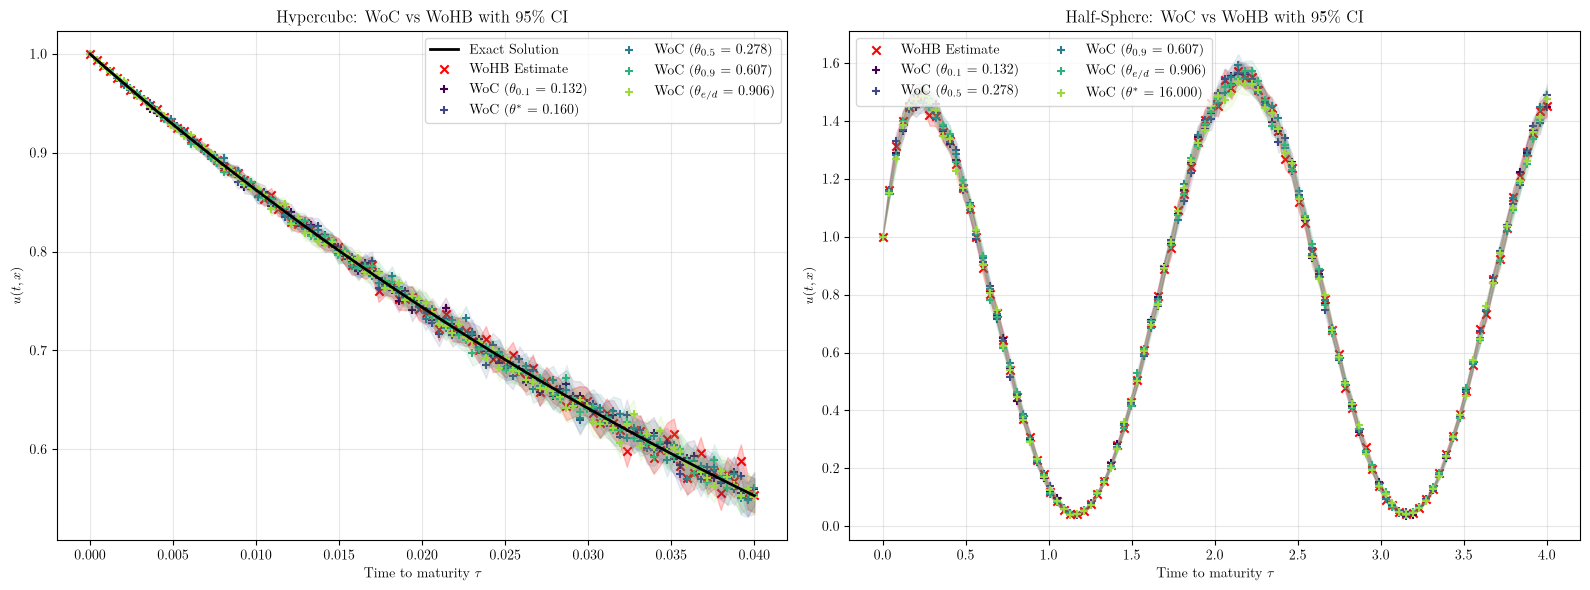

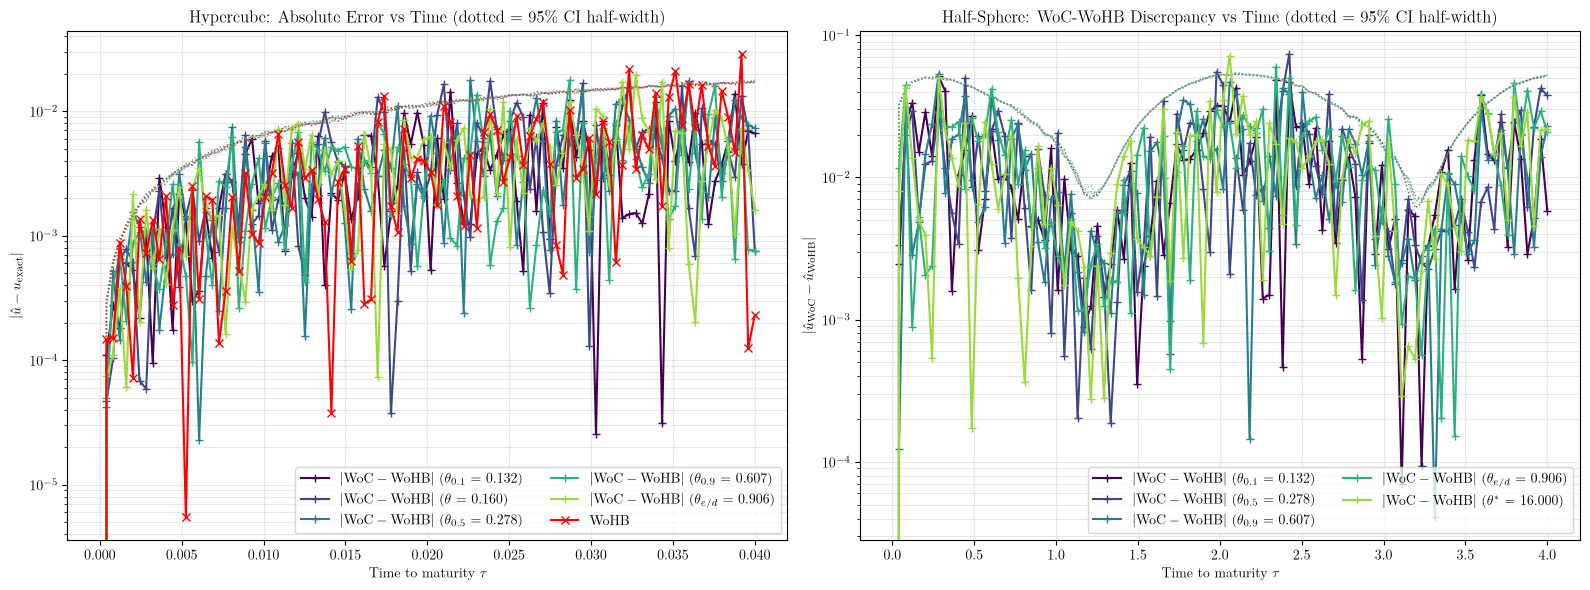

In [41]:
exp1_results = load_pickle(RESULTS_DIR / 'exp1_results.pkl')

# ── EXPERIMENT 1: PLOTTING ──────────────────────────────────────────────────────────────

# ── FIGURE 1: SOLUTION OVER TIME ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp1_results[name]
    x = cfg['x0']
    times = cfg['times'][1]
    theta_plot = list(res['theta_values'])
    th_star = theta_star(cfg['domain'], x, cfg['T'][1])
    theta_colors = {theta: c for theta, c in zip(theta_plot, plt.cm.viridis(np.linspace(0.0, 0.85, len(theta_plot))))}

    if res['exact'] is not None:
        ax.plot(times, res['exact'], label='Exact Solution', color='black', linewidth=2)

    ax.scatter(times, res['wohb_mean'], label='WoHB Estimate', color='red', marker='x')
    ax.fill_between(times, res['wohb_mean'] - res['wohb_conf_int'], res['wohb_mean'] + res['wohb_conf_int'], color='red', alpha=0.2)

    for theta in theta_plot:
        means = res['woc_by_theta'][theta]['mean']
        conf_int = res['woc_by_theta'][theta]['conf_int']
        ax.scatter(times, means, label = rf'WoC ({theta_label(theta, th_star)} = {theta:.3f})', marker='+', color=theta_colors[theta])
        ax.fill_between(times, means - conf_int, means + conf_int, alpha=0.1, color=theta_colors[theta])

    ax.set_xlabel(r'Time to maturity $\tau$')
    ax.set_ylabel(r'$u(t, x)$')
    ax.set_title(f'{name}: WoC vs WoHB with 95{PCT} CI')
    ax.legend(ncol=2)
    ax.grid(alpha=0.3)

plt.tight_layout()
filename = 'experiment1_solution_over_time.pdf'
save_fig(filename)
plt.show()


# ── FIGURE 2: ACCURACY OVER TIME ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp1_results[name]
    times = cfg['times'][1]
    theta_plot = list(res['theta_values'])
    theta_colors = {theta: c for theta, c in zip(theta_plot, plt.cm.viridis(np.linspace(0.0, 0.85, len(theta_plot))))}

    if res['exact'] is not None:
        for theta in theta_plot:
            err = res['woc_err_by_theta'][theta]
            ci = res['woc_by_theta'][theta]['conf_int']
            ax.plot(times, err, label = rf'$|\mathrm{{WoC}} - \mathrm{{WoHB}}|$ ({theta_label(theta, th_star)} = {theta:.3f})', marker ='+', color=theta_colors[theta])
            ax.plot(times, ci, linestyle=':', color = theta_colors[theta], linewidth=1, alpha=0.7)
        ax.plot(times, res['wohb_err'], marker='x', color='red', label='WoHB')
        ax.plot(times, res['wohb_conf_int'], linestyle=':', color='red', linewidth=1, alpha=0.7)
        ax.set_ylabel(r'$|\hat{u} - u_{\mathrm{exact}}|$')
        ax.set_title(f'{name}: Absolute Error vs Time (dotted = 95{PCT} CI half-width)')
    else:
        for theta in theta_plot:
            gap = res['woc_wohb_gap_by_theta'][theta]
            gap_ci = res['woc_wohb_gap_ci_by_theta'][theta]
            ax.plot(times, gap, label = rf'$|\mathrm{{WoC}} - \mathrm{{WoHB}}|$ ({theta_label(theta, th_star)} = {theta:.3f})', marker ='+', color=theta_colors[theta])
            ax.plot(times, gap_ci, linestyle=':', color = theta_colors[theta], linewidth=1, alpha=0.7)
        ax.set_ylabel(r'$|\hat{u}_{\mathrm{WoC}} - \hat{u}_{\mathrm{WoHB}}|$')
        ax.set_title(f'{name}: WoC-WoHB Discrepancy vs Time (dotted = 95{PCT} CI half-width)')

    ax.set_yscale('log')
    ax.set_xlabel(r'Time to maturity $\tau$')
    ax.legend(ncol=2)
    ax.grid(alpha=0.3, which='both')

plt.tight_layout()
save_fig('experiment1_accuracy_over_time.pdf')
plt.show()

## Experiment 2: distribution of steps and space-exit proportion
For each $\theta$: space-exit proportion over time and the step distribution at the horizon $T$. The *small-$\theta$ sweep* adds the grid `THETA_SWEEP_GRID` to the $\theta$ values, at the same $T$ and tolerances, to show the U-shape of the average steps.

In [53]:
if RECOMPUTE[2] or not (RESULTS_DIR / 'exp2_results.pkl').exists():
    exp2_results = {}
    exp2_time = time.time()
    tol_space = tol_space_for(epsilon_value, DIM)
    tol_time = tol_time_for(epsilon_value)

    for cfg in domains_config:
        # Extract configuration parameters
        name = cfg['name']
        domain = cfg['domain']
        f = cfg['f']
        g = cfg['g']
        scale = cfg['scale']
        x = cfg['x0']
        T_total = cfg['T'][2]
        times = cfg['times'][2]
        theta_list = cfg['theta_values']
        if INCLUDE_THETA_STAR:
            theta_list = np.unique(np.append(theta_list, theta_star(domain, x, T_total)))

        print(f'\n--- {name} ---')

        prop_space_woc_by_theta = {}
        steps_by_theta = {}
        space_frac_by_theta = {}

        # Sweep over theta values for WoC to compute the space exit proportions over time
        for theta in theta_list:
            print('\n--------------------------------')
            print(f'    WoC with theta = {theta:.4f}…')
            theta_start = time.time()
            WOC_theta = WalkOnCylinders(DIM, domain, theta, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                        seed=seed_for('exp2', name, 'woc', theta), use_spatial_boundary=True)
            use_terminal_eps = WOC_theta.p_terminal <= 1.0 / N_cutoff
            print(f'        H_theta = {WOC_theta.H_s:.6f} | p_terminal = {WOC_theta.p_terminal:.6f} '
                  f'| E[N] = {1.0 / max(WOC_theta.p_terminal, 1e-15):.1f} | terminal_eps = {use_terminal_eps}')

            prop_space_woc = []

            print(f'    Started WoC Space Exit Proportions with theta = {theta:.4f}…')
            for t in times:
                _, _, woc_space_flags = heat_mc_solution_vector_WOC(WOC_theta, t, x, f, g, DIM, scale, N_PATHS_exp2, tol_space, tol_time)
                prop_space_woc.append(np.mean(woc_space_flags))

            prop_space_woc_by_theta[theta] = prop_space_woc

            print(f'    WoC Steps Distribution with theta = {theta:.4f}…')
            _, woc_steps, woc_flags = heat_mc_solution_vector_WOC(WOC_theta, T_total, x, f, g, DIM, scale, N_PATHS_exp2, tol_space, tol_time)
            steps_by_theta[theta] = np.asarray(woc_steps)
            space_frac_by_theta[theta] = float(np.mean(woc_flags))

            print(f'    Finished theta = {theta:.4f} in {time.time() - theta_start:.2f} seconds. | mean_steps={steps_by_theta[theta].mean():.1f} | space_exit_frac={space_frac_by_theta[theta]:.3f}')

        WOHB_start = time.time()
        WOHB = WalkOnHeatBalls(DIM, domain, max_steps=1_000_000, seed=seed_for('exp2', name, 'wohb'), use_spatial_boundary=True)

        prop_space_wohb = []

        # Walk on Heat Balls to compute the space exit proportions over time
        print(f'    Started WoHB with epsilon = {epsilon_value}…')
        for t in times:
            _, _, wohb_space_flags = heat_mc_solution_vector_WOHB(WOHB, t, x, f, g, DIM, scale, N_PATHS_exp2, epsi=epsilon_value)
            prop_space_wohb.append(np.mean(wohb_space_flags))

        print(f'    Finished WoHB Space Exit Proportions in {time.time() - WOHB_start:.2f} seconds.')

        _, wohb_steps, _ = heat_mc_solution_vector_WOHB(WOHB, T_total, x, f, g, DIM, scale, N_PATHS_exp2, epsi=epsilon_value)
        print(f'    Finished WoHB Steps Distribution.')

        avg_steps_by_theta = {theta: np.mean(steps) for theta, steps in steps_by_theta.items()}
        avg_steps_wohb = np.mean(wohb_steps)

        # Small-theta sweep (U-shape): the grid thetas plus this dimension's simulated thetas, same T and tolerances
        avg_sweep = dict(avg_steps_by_theta)
        sweep_extra = [th for th in THETA_SWEEP_GRID if not np.any(np.isclose(th, theta_list))]
        sweep_steps = {}
        print(f'    Started theta sweep ({len(sweep_extra)} extra values)…')
        for th in sweep_extra:
            W_sw = WalkOnCylinders(DIM, domain, float(th), N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                   seed=seed_for('exp2', name, 'sweep', th), use_spatial_boundary=True)
            _, st_sw, _ = heat_mc_solution_vector_WOC(W_sw, T_total, x, f, g, DIM, scale, N_PATHS_exp2, tol_space, tol_time)
            sweep_steps[float(th)] = np.asarray(st_sw)
            avg_sweep[float(th)] = float(np.mean(st_sw))
            print(f'        theta = {th:.4f}: mean_steps = {avg_sweep[float(th)]:.2f}')
        theta_sweep = np.array(sorted(avg_sweep))
        avg_steps_sweep = np.array([avg_sweep[t] for t in theta_sweep])

        exp2_results[name] = {
            'prop_space_woc_by_theta': prop_space_woc_by_theta,
            'prop_space_wohb': prop_space_wohb,
            'steps_woc_by_theta': steps_by_theta,
            'space_frac_by_theta': space_frac_by_theta,
            'wohb_steps': wohb_steps,
            'avg_steps_by_theta': avg_steps_by_theta,
            'avg_steps_wohb': avg_steps_wohb,
            'theta_sweep': theta_sweep,
            'avg_steps_sweep': avg_steps_sweep,
            'sweep_steps': sweep_steps,
            'theta_list': theta_list
        }

    print(f"\nExperiment 2 completed in {time.time() - exp2_time:.2f} seconds.")
    save_pickle(exp2_results, RESULTS_DIR / 'exp2_results.pkl')
else:
    exp2_results = load_pickle(RESULTS_DIR / 'exp2_results.pkl')
    print('Loaded saved results from exp2_results.pkl')


--- Hypercube ---

--------------------------------
    WoC with theta = 0.0800…
        H_theta = 0.010891 | p_terminal = 0.989109 | E[N] = 1.0 | terminal_eps = False
    Started WoC Space Exit Proportions with theta = 0.0800…
    WoC Steps Distribution with theta = 0.0800…
    Finished theta = 0.0800 in 46.97 seconds. | mean_steps=1.1 | space_exit_frac=0.003

--------------------------------
    WoC with theta = 0.1322…
        H_theta = 0.100000 | p_terminal = 0.900000 | E[N] = 1.1 | terminal_eps = False
    Started WoC Space Exit Proportions with theta = 0.1322…
    WoC Steps Distribution with theta = 0.1322…
    Finished theta = 0.1322 in 26.40 seconds. | mean_steps=1.2 | space_exit_frac=0.002

--------------------------------
    WoC with theta = 0.2776…
        H_theta = 0.500000 | p_terminal = 0.500000 | E[N] = 2.0 | terminal_eps = False
    Started WoC Space Exit Proportions with theta = 0.2776…
    WoC Steps Distribution with theta = 0.2776…
    Finished theta = 0.2776 in 15

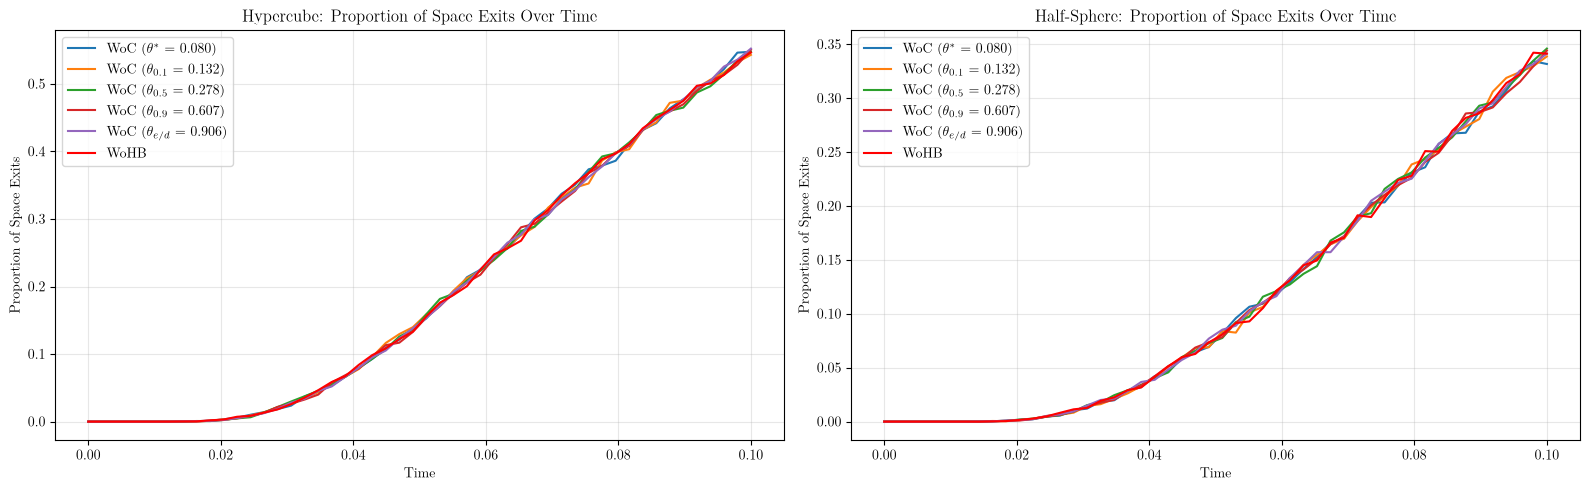

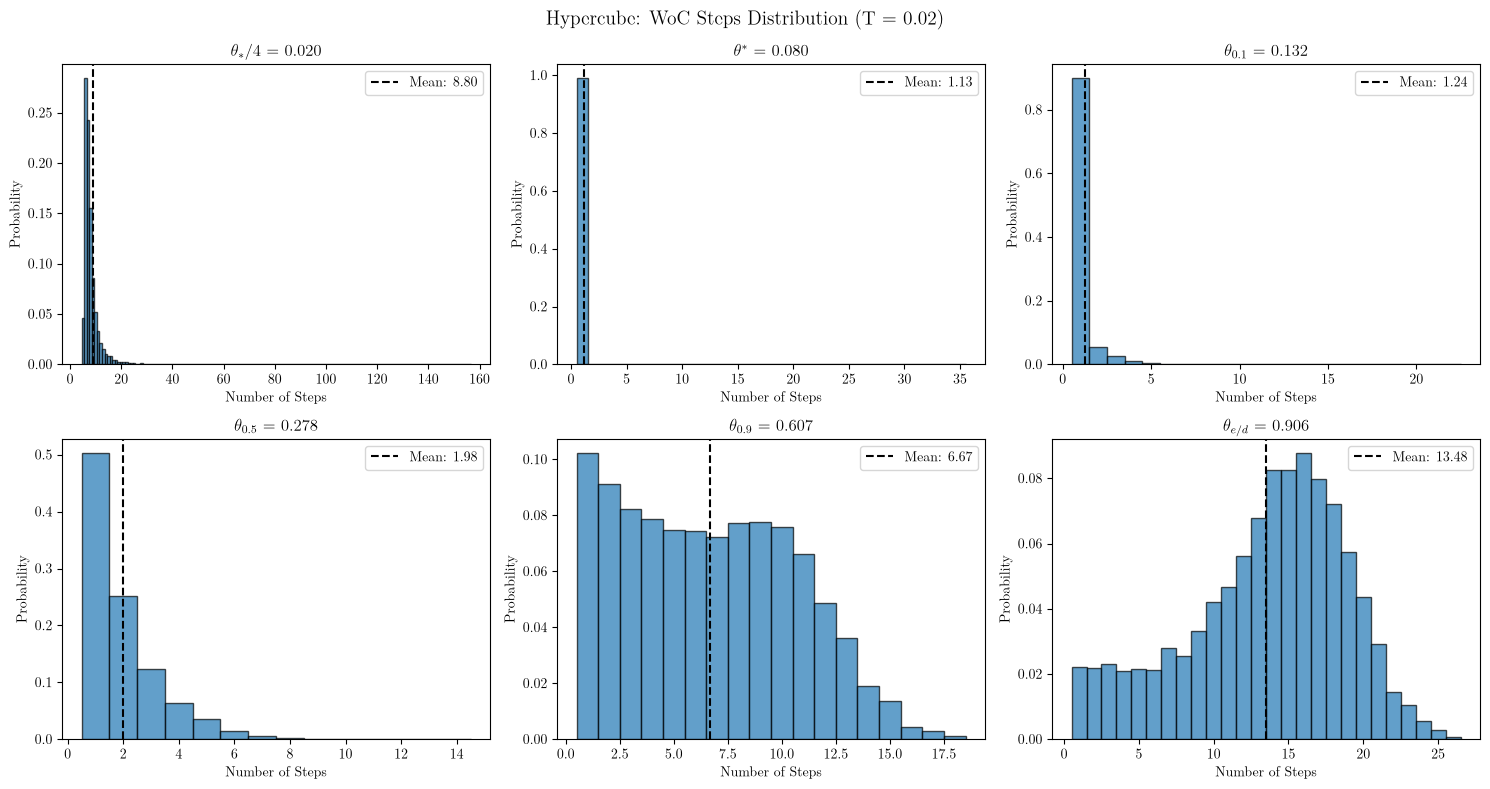

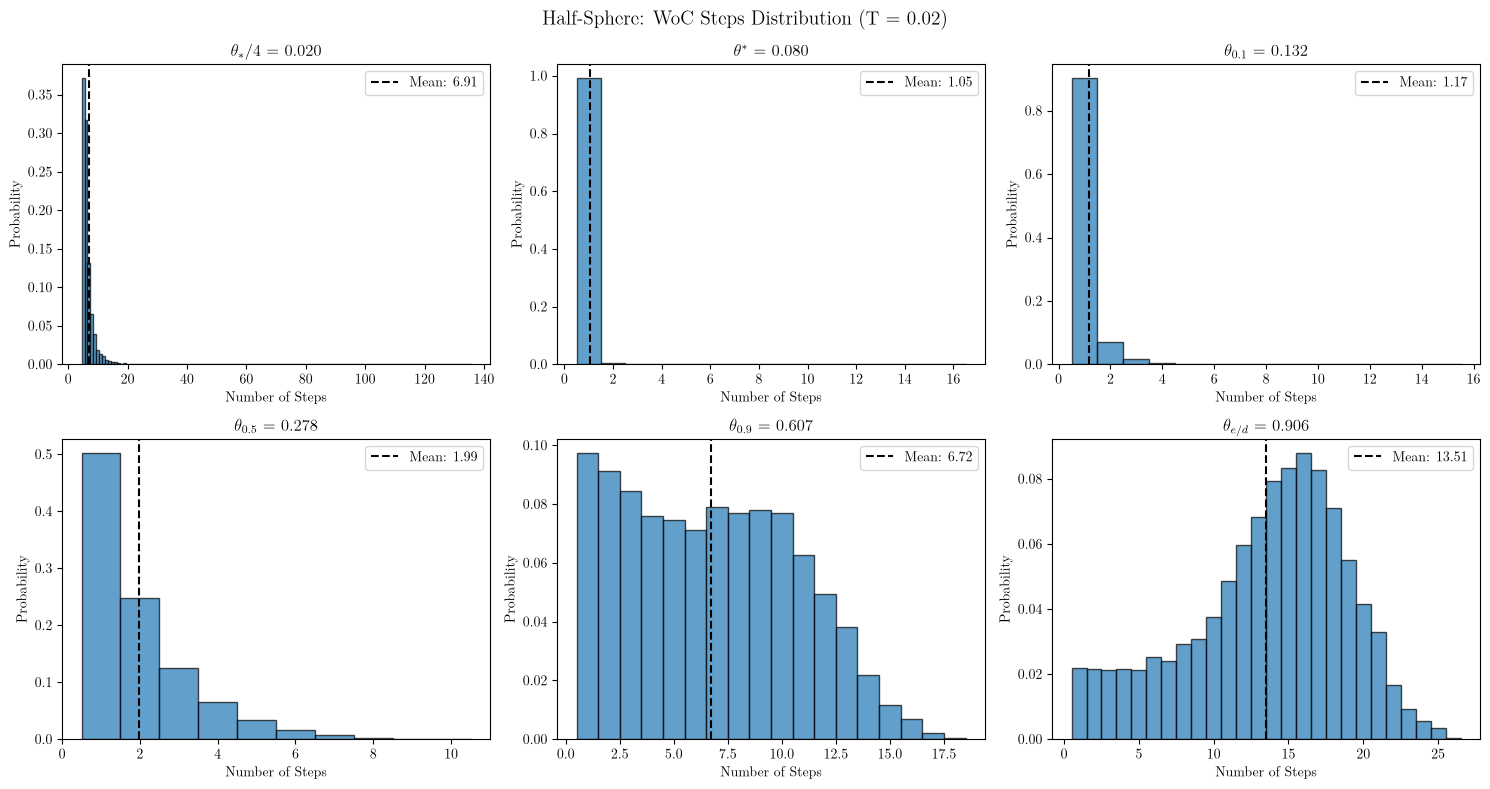

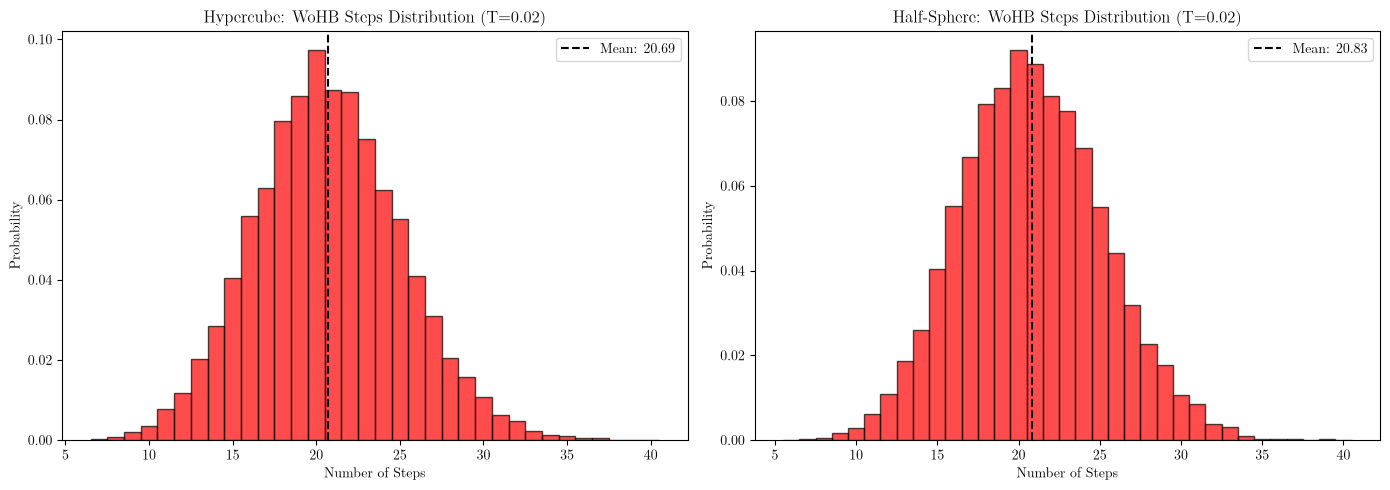

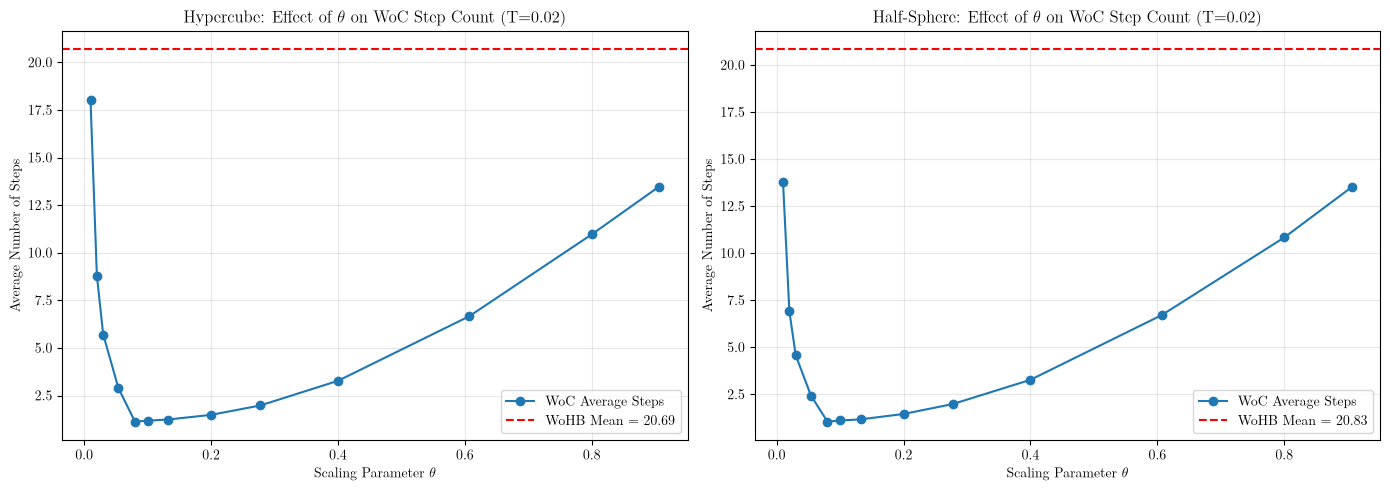

In [ ]:
exp2_results = load_pickle(RESULTS_DIR / 'exp2_results.pkl')

# ── EXPERIMENT 2: PLOTTING ────────────────────────────────────────────────

# ── Figure 1: Space Exit Proportions vs time ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp2_results[name]
    times = cfg['times'][2]
    th_star = theta_star(cfg['domain'], cfg['x0'], cfg['T'][2])

    for theta in res['theta_list']:
        ax.plot(times, res['prop_space_woc_by_theta'][theta], label = rf'WoC ({theta_label(theta, th_star)} = {theta:.3f})')

    ax.plot(times, res['prop_space_wohb'], label='WoHB', color='red')

    ax.set_xlabel('Time')
    ax.set_ylabel('Proportion of Space Exits')
    ax.set_title(f'{name}: Proportion of Space Exits Over Time')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
filename = 'experiment2_space_exit_proportions.pdf'
save_fig(filename)
plt.show()

# ── Figure 2: WoC Step Count Histograms (one figure per domain) ──────────
from matplotlib.gridspec import GridSpec

for cfg in domains_config:
    name = cfg['name']
    res = exp2_results[name]
    T_total = cfg['T'][2]
    th_star = theta_star(cfg['domain'], cfg['x0'], T_total)
    steps_all = dict(res['steps_woc_by_theta'])
    th_low = min(res['sweep_steps'], key = lambda t: abs(t-th_star / 4))
    steps_all[th_low] = res['sweep_steps'][th_low]
    theta_plot = sorted(steps_all)

    ncols = 3
    n = len(theta_plot)
    nrows = int(np.ceil(n / ncols))
    fig = plt.figure(figsize=(5 * ncols, 4 * nrows))
    gs = GridSpec(nrows, 2 * ncols, figure=fig)

    for i, theta in enumerate(theta_plot):
        row, col = divmod(i, ncols)
        items = min(ncols, n - row * ncols)
        start = (ncols - items) + 2 * col
        ax = fig.add_subplot(gs[row, start:start + 2])

        steps = steps_all[theta]
        upper = np.percentile(steps, 99.9)
        steps_trimmed = steps[steps <= upper]
        bins = np.arange(min(steps_trimmed) - 0.5, max(steps_trimmed) + 1.5, 1)

        ax.hist(steps_trimmed, bins=bins, density=True, edgecolor='black', alpha=0.7)
        ax.axvline(np.mean(steps), color='black', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(steps):.2f}')
        ax.set_title(rf'{theta_label(theta, th_star)} = {theta:.3f}')
        ax.set_xlabel('Number of Steps')
        ax.set_ylabel('Probability')
        ax.legend()

    fig.suptitle(f'{name}: WoC Steps Distribution (T = {T_total:g})', fontsize=14)
    plt.tight_layout()
    save_fig(f'experiment2_woc_step_count_histograms_{name.lower()}.pdf')
    plt.show()


# ── Figure 3: WoHB Step Count Histograms ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14,5))

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp2_results[name]

    steps = res['wohb_steps']
    bins = np.arange(min(steps) - 0.5, max(steps) + 1.5, 1)
    ax.hist(steps, bins=bins, density=True, edgecolor='black', alpha=0.7, color='red')
    ax.axvline(res['avg_steps_wohb'], color='black', linestyle='--', linewidth=1.5, label=f'Mean: {res["avg_steps_wohb"]:.2f}')
    ax.set_title(f'{name}: WoHB Steps Distribution (T={cfg["T"][2]:.2f})')
    ax.set_xlabel('Number of Steps')
    ax.set_ylabel('Probability')
    ax.legend()

plt.tight_layout()
filename = 'experiment2_wohb_step_count_histograms.pdf'
save_fig(filename)
plt.show()

# ── Figure 4: Average steps vs theta (small-theta sweep + simulated thetas) ───────────────
fig, axes = plt.subplots(1, 2, figsize=(14,5))

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp2_results[name]

    ax.plot(res['theta_sweep'], res['avg_steps_sweep'], marker='o', label='WoC Average Steps')
    ax.axhline(res['avg_steps_wohb'], color='red', linestyle='--', label=f'WoHB Mean = {res["avg_steps_wohb"]:.2f}')
    ax.set_xscale('log')
    ax.set_xlabel(r'Scaling Parameter $\theta$')
    ax.set_ylabel('Average Number of Steps')
    ax.set_title(rf'{name}: Effect of $\theta$ on WoC Step Count (T={cfg["T"][2]:.2f})')
    ax.legend()
    ax.grid(alpha=0.3, which='both')

plt.tight_layout()
filename = 'experiment2_avg_steps_vs_theta.pdf'
save_fig(filename)
plt.show()

## Experiment 3: varying $\epsilon$ and the initial position
(a) Average steps against the tolerance, with the coupled tolerances $\epsilon_0=\epsilon$ and $\epsilon_1=\sqrt{\epsilon d/e}$ at two horizons $T$; (b) average steps and space-exit proportion against the initial position.

In [64]:
# ── EXPERIMENT 3: initial-position sweeps ──────────────────────────────────────────────────────────────
n_values = np.array(eps_exponents)

pos_sweep = {
    'Hypercube': [np.full(DIM, u, dtype=np.float64) for u in np.linspace(_offset, L/2, n_points)],
    'Half-Sphere': [np.array([u] + [0.0]*(DIM - 1), dtype=np.float64) for u in np.linspace(0 + _offset, R - _offset, n_points)]
}

pos_axis = {
    'Hypercube': np.linspace(_offset, L/2, n_points),
    'Half-Sphere': np.linspace(0 + _offset, R - _offset, n_points)
}

pos_xlabel = {
    'Hypercube': r'Initial Position $x_0$ ($x_0 = (u, u, u)$)',
    'Half-Sphere': r'Initial Position $x_0$ ($x_0 = (u, 0, 0)$)',
}

In [65]:
if RECOMPUTE[3] or not (RESULTS_DIR / 'exp3_results.pkl').exists():
    exp3_results = {}

    for cfg in domains_config:
        name = cfg['name']
        domain = cfg['domain']
        f = cfg['f']
        g = cfg['g']
        scale = cfg['scale']
        x = cfg['x0']
        T_total = cfg['T'][3]   # Total time for position sweep


        tol_time = tol_time_for(epsilon_value_exp3)
        tol_space = tol_space_for(epsilon_value_exp3, DIM)

        print(f'\n--- {name} ---')

        WOHB = WalkOnHeatBalls(DIM, domain, max_steps=1_000_000, seed=seed_for('exp3', name, 'wohb'), use_spatial_boundary=True)

        # Epsilon sweep
        avg_steps_woc_eps_by_theta = {T: {} for T in T_eps_sweep}
        space_frac_woc_eps_by_theta = {T: {} for T in T_eps_sweep}
        avg_steps_wohb_eps = {T: [] for T in T_eps_sweep}
        space_frac_wohb_eps = {T: [] for T in T_eps_sweep}

        for T_eps in T_eps_sweep:
            print(f'  -- T = {T_eps:.2f} --')

            theta_list_eps = cfg['theta_values']
            if INCLUDE_THETA_STAR:
                theta_list_eps = np.unique(np.append(theta_list_eps, theta_star(domain, x, T_eps)))

            for theta in theta_list_eps:
                print(f'    WoC with theta = {theta:.4f} epsilon sweep…')
                WOC_theta = WalkOnCylinders(DIM, domain, theta, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                            seed=seed_for('exp3', name, 'eps', T_eps, theta), use_spatial_boundary=True)

                avg_steps_woc_eps_by_theta[T_eps][theta] = []
                space_frac_woc_eps_by_theta[T_eps][theta] = []

                for eps in eps_values:
                    # Coupled tolerances: epsilon_0 = eps and epsilon_1 = sqrt(eps * d / e)
                    tol_space_eps = tol_space_for(eps, DIM)
                    tol_time_eps = eps
                    _, woc_steps_eps, woc_space_flags_eps = heat_mc_solution_vector_WOC(WOC_theta, T_eps, x, f, g, DIM, scale, N_PATHS_exp3, tol_space_eps, tol_time_eps)

                    avg_steps_woc_eps_by_theta[T_eps][theta].append(np.mean(woc_steps_eps))
                    space_frac_woc_eps_by_theta[T_eps][theta].append(woc_space_flags_eps.mean())

            for eps in eps_values:
                print(f'    WoHB with epsilon = {eps:.4e}…')
                _, wohb_steps_eps, wohb_space_flags_eps = heat_mc_solution_vector_WOHB(WOHB, T_eps, x, f, g, DIM, scale, N_PATHS_exp3, epsi=eps)

                avg_steps_wohb_eps[T_eps].append(np.mean(wohb_steps_eps))
                space_frac_wohb_eps[T_eps].append(wohb_space_flags_eps.mean())

        # Initial position sweep
        avg_steps_woc_u_by_theta = {}
        prop_space_woc_u_by_theta = {}

        for theta in cfg['theta_values']:
            print(f'    WoC with theta = {theta:.4f} initial position sweep…')
            WOC_theta = WalkOnCylinders(DIM, domain, theta, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                        seed=seed_for('exp3', name, 'pos', theta), use_spatial_boundary=True)

            avg_steps_u = []
            prop_space_u = []

            for x_pos in pos_sweep[name]:
                _, woc_steps_u, woc_space_flags_u = heat_mc_solution_vector_WOC(WOC_theta, T_total, x_pos, f, g, DIM, scale, N_PATHS_exp3, tol_space, tol_time)

                avg_steps_u.append(np.mean(woc_steps_u))
                prop_space_u.append(np.mean(woc_space_flags_u))

            avg_steps_woc_u_by_theta[theta] = np.array(avg_steps_u)
            prop_space_woc_u_by_theta[theta] = np.array(prop_space_u)

        avg_steps_wohb_u = []
        prop_space_wohb_u = []

        for x_pos in pos_sweep[name]:
            _, wohb_steps_u, wohb_space_flags_u = heat_mc_solution_vector_WOHB(WOHB, T_total, x_pos, f, g, DIM, scale, N_PATHS_exp3, epsi=epsilon_value_exp3)

            avg_steps_wohb_u.append(np.mean(wohb_steps_u))
            prop_space_wohb_u.append(np.mean(wohb_space_flags_u))

        print('    WoC with theta = theta_*(x0) initial position sweep...')
        theta_star_u = []
        theta_star_raw = []
        avg_steps_star_u = []
        prop_space_star_u = []
        for x_pos in pos_sweep[name]:
            th_raw = float(theta_star(domain, x_pos, T_total))
            th = float(np.clip(th_raw, THETA_STAR_MIN, THETA_STAR_MAX))
            W = WalkOnCylinders(DIM, domain, th, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                seed=seed_for('exp3', name, 'pos_star', float(x_pos[0])), use_spatial_boundary=True)
            _, st, fl = heat_mc_solution_vector_WOC(W, T_total, x_pos, f, g, DIM, scale, N_PATHS_exp3, tol_space, tol_time)
            theta_star_u.append(th)
            theta_star_raw.append(th_raw)
            avg_steps_star_u.append(np.mean(st))
            prop_space_star_u.append(np.mean(fl))

        exp3_results[name] = {
            'T_eps_sweep': T_eps_sweep,
            'avg_steps_woc_eps_by_theta': avg_steps_woc_eps_by_theta,
            'avg_steps_wohb_eps': avg_steps_wohb_eps,
            'space_frac_woc_eps_by_theta': space_frac_woc_eps_by_theta,
            'space_frac_wohb_eps': space_frac_wohb_eps,
            'avg_steps_woc_u_by_theta': avg_steps_woc_u_by_theta,
            'prop_space_woc_u_by_theta': prop_space_woc_u_by_theta,
            'avg_steps_wohb_u': np.array(avg_steps_wohb_u),
            'prop_space_wohb_u': np.array(prop_space_wohb_u),
            'theta_star_u': np.array(theta_star_u),
            'theta_star_raw': np.array(theta_star_raw),
            'avg_steps_star_u': np.array(avg_steps_star_u),
            'prop_space_star_u': np.array(prop_space_star_u)
        }
    save_pickle(exp3_results, RESULTS_DIR / 'exp3_results.pkl')
else:
    exp3_results = load_pickle(RESULTS_DIR / 'exp3_results.pkl')
    print('Loaded saved results from exp3_results.pkl')


--- Hypercube ---
  -- T = 0.02 --
    WoC with theta = 0.0800 epsilon sweep…
    WoC with theta = 0.1322 epsilon sweep…
    WoC with theta = 0.2776 epsilon sweep…
    WoC with theta = 0.6070 epsilon sweep…
    WoC with theta = 0.9061 epsilon sweep…
    WoHB with epsilon = 5.0000e-03…
    WoHB with epsilon = 2.5000e-03…
    WoHB with epsilon = 1.2500e-03…
    WoHB with epsilon = 6.2500e-04…
    WoHB with epsilon = 3.1250e-04…
    WoHB with epsilon = 1.5625e-04…
    WoHB with epsilon = 7.8125e-05…
    WoHB with epsilon = 3.9063e-05…
    WoHB with epsilon = 1.9531e-05…
    WoHB with epsilon = 9.7656e-06…
    WoHB with epsilon = 4.8828e-06…
    WoHB with epsilon = 2.4414e-06…
    WoHB with epsilon = 1.2207e-06…
    WoHB with epsilon = 6.1035e-07…
    WoHB with epsilon = 3.0518e-07…
    WoHB with epsilon = 1.5259e-07…
  -- T = 0.08 --
    WoC with theta = 0.1322 epsilon sweep…
    WoC with theta = 0.2776 epsilon sweep…
    WoC with theta = 0.3200 epsilon sweep…
    WoC with theta = 0.6070

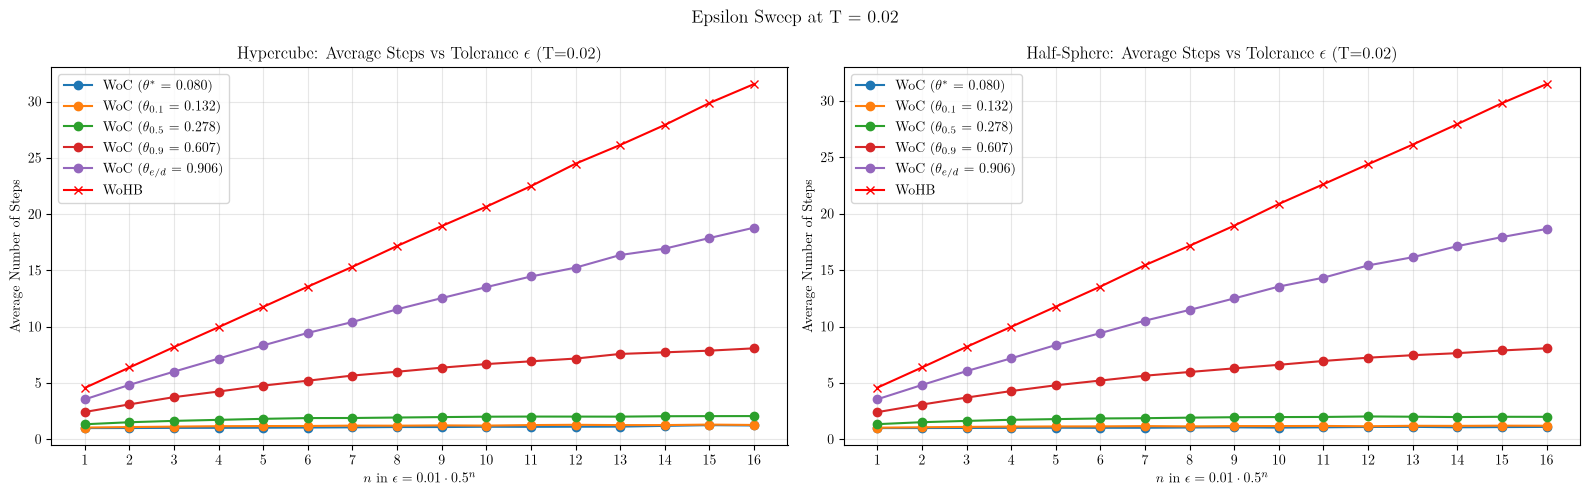

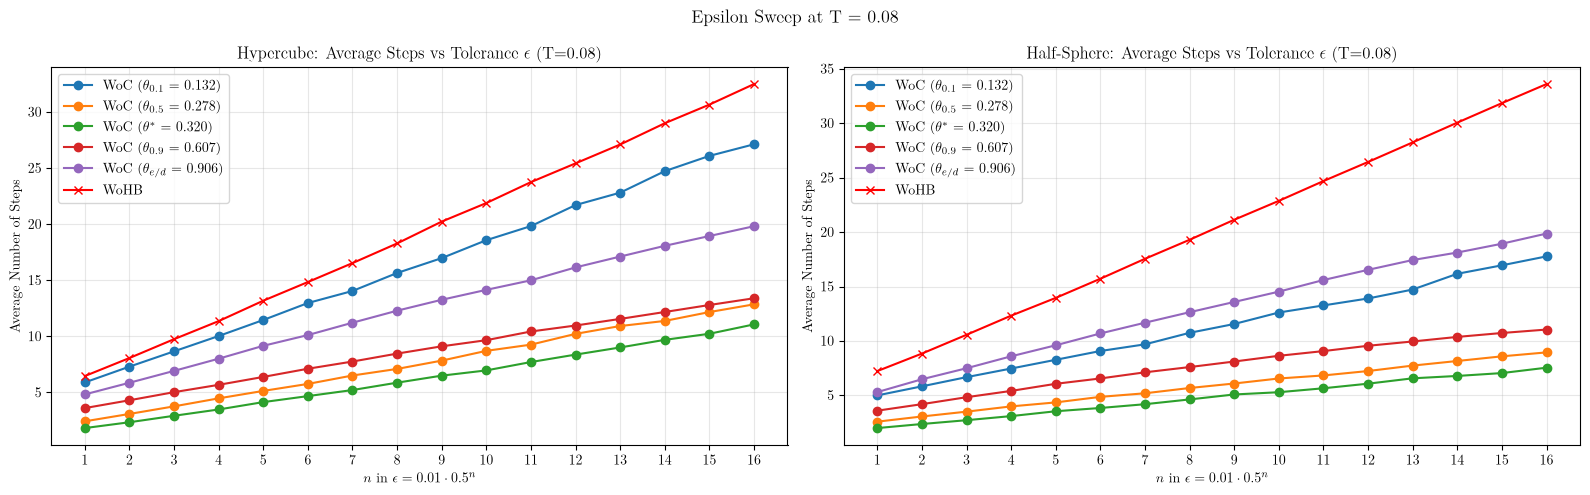

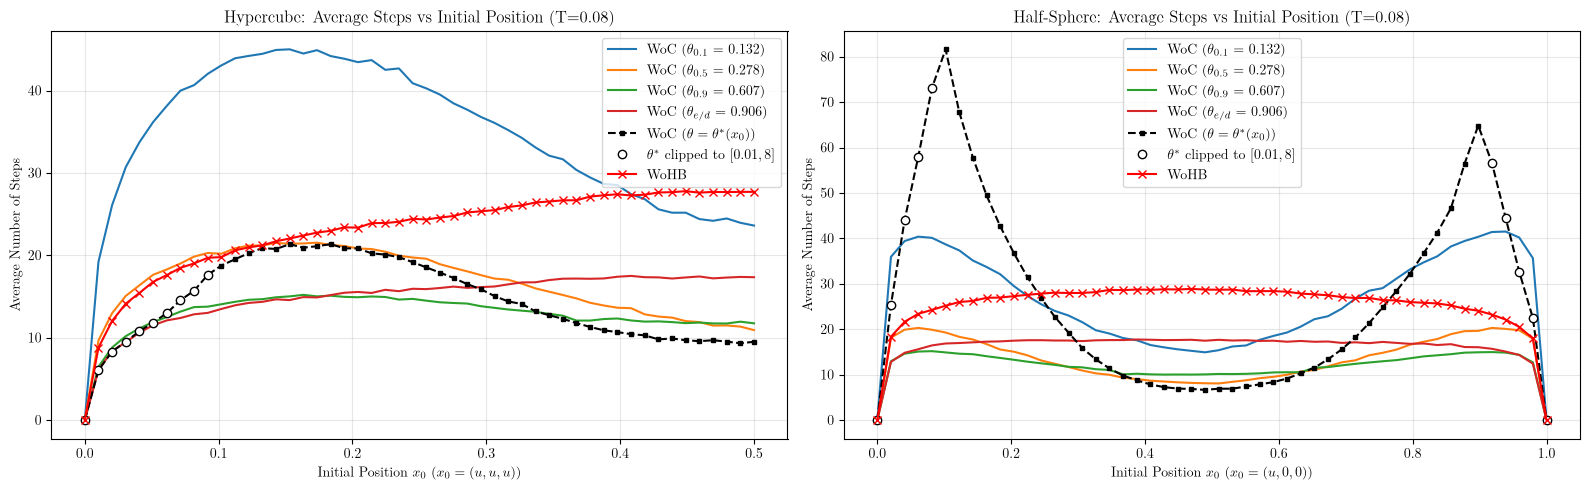

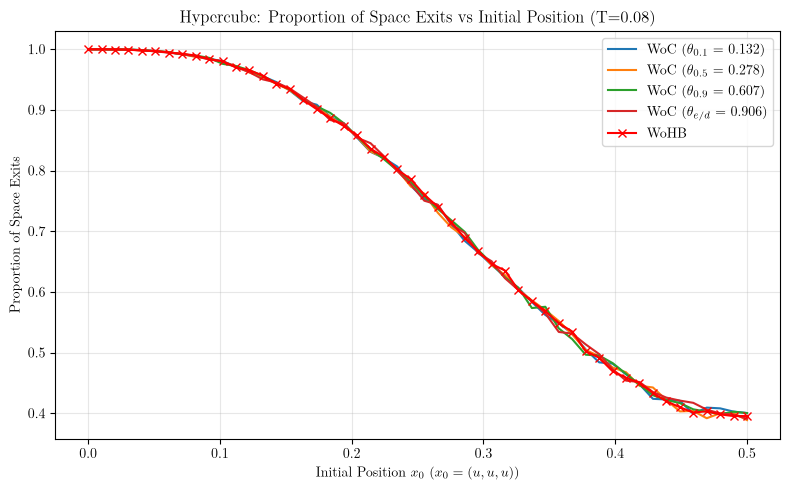

In [73]:
exp3_results = load_pickle(RESULTS_DIR / 'exp3_results.pkl')

# ── EXPERIMENT 3: PLOTTING ────────────────────────────────────────────────

# ── Figure 1: Average Steps vs Epsilon ────────────────────────────────────────────────
for T_eps in exp3_results['Hypercube']['T_eps_sweep']:
    fig, axes = plt.subplots(1, 2, figsize=(16,5))

    for ax, cfg in zip(axes, domains_config):
        name = cfg['name']
        res = exp3_results[name]

        th_star = theta_star(cfg['domain'], cfg['x0'], T_eps)
        for theta in sorted(res['avg_steps_woc_eps_by_theta'][T_eps]):
            ax.plot(n_values, res['avg_steps_woc_eps_by_theta'][T_eps][theta], label=rf'WoC ({theta_label(theta, th_star)} = {theta:.3f})', marker='o')

        ax.plot(n_values, res['avg_steps_wohb_eps'][T_eps], label='WoHB', color='red', marker='x')
        ax.set_xlabel(rf'$n$ in $\epsilon = {EPS_SCALE:g} \cdot 0.5^n$')
        ax.set_xticks(n_values)
        ax.set_ylabel('Average Number of Steps')
        ax.set_title(f'{name}: Average Steps vs Tolerance $\\epsilon$ (T={T_eps:.2f})')
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f'Epsilon Sweep at T = {T_eps:.2f}', fontsize=13)
    plt.tight_layout()
    save_fig(f'experiment3_avg_steps_vs_epsilon_T{T_eps:.2f}.pdf')
    plt.show()

# ── Figure 2: Average Steps vs Initial Position ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16,5))

for ax, cfg in zip(axes, domains_config):
    name = cfg['name']
    res = exp3_results[name]
    u_axis = pos_axis[name]

    for theta in cfg['theta_values_plot']:
        ax.plot(u_axis, res['avg_steps_woc_u_by_theta'][theta], label=rf'WoC ({theta_label(theta)} = {theta:.3f})')

    ax.plot(u_axis, res['avg_steps_star_u'], color='black', linestyle='--', marker='s', markersize=3, label=r'WoC ($\theta=\theta^*(x_0)$)')
    clipped = ~np.isclose(res['theta_star_u'], res['theta_star_raw'])
    if clipped.any():
        ax.plot(u_axis[clipped], res['avg_steps_star_u'][clipped], marker='o', markerfacecolor='white', markeredgecolor='black',
                color='black', linestyle='none', label=rf'$\theta^*$ clipped to $[{THETA_STAR_MIN:g}, {THETA_STAR_MAX:g}]$')

    ax.plot(u_axis, res['avg_steps_wohb_u'], label='WoHB', color='red', marker='x')
    ax.set_xlabel(pos_xlabel[name])
    ax.set_ylabel('Average Number of Steps')
    ax.set_title(f'{name}: Average Steps vs Initial Position (T={cfg["T"][3]:.2f})')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
save_fig('experiment3_avg_steps_vs_initial_position.pdf')
plt.show()

# ── Figure 3: Proportion of Space Exits vs Initial Position ────────────────────────────────────────────────
cfg = domains_config[0]
res = exp3_results['Hypercube']
u_axis = pos_axis['Hypercube']

fig, ax = plt.subplots(figsize=(8,5))

for theta in cfg['theta_values_plot']:
    ax.plot(u_axis, res['prop_space_woc_u_by_theta'][theta], label=rf'WoC ({theta_label(theta)} = {theta:.3f})')

ax.plot(u_axis, res['prop_space_wohb_u'], label='WoHB', color='red', marker='x')
ax.set_xlabel(pos_xlabel['Hypercube'])
ax.set_ylabel('Proportion of Space Exits')
ax.set_title(f'Hypercube: Proportion of Space Exits vs Initial Position (T={cfg["T"][3]:.2f})')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
save_fig('experiment3_space_exit_vs_initial_position.pdf')
plt.show()

## Experiment 4: dimension scaling
Average steps against the dimension for $\theta_{0.1}(d), \theta_{0.5}(d), \theta_{0.9}(d)$ (and optionally $e/d$ and $\theta_{\text{large}}$), for several domain sizes and tolerances. The loop writes a checkpoint CSV after every dimension; with `RESUME_EXP4 = True` an interrupted run continues from it.

In [74]:
# ── EXPERIMENT 4: SIMULATION ─────────────────────────────────────────────
CHECKPOINT_PATH = RESULTS_DIR / 'woc_wohb_dim_scaling_results.csv'

theta_q_by_dim = {int(d_): get_theta_quantiles(int(d_), THETA_QUANTILE_LEVELS) for d_ in DIM_range} # theta_p(d) for every dimension

results_exp4 = []
done_exp4 = set()
if RESUME_EXP4 and not RECOMPUTE[4] and CHECKPOINT_PATH.exists():
    results_exp4 = pd.read_csv(CHECKPOINT_PATH).to_dict('records')
    done_exp4 = {(r['domain'], float(r['scale']), int(r['dimension']), float(r['epsilon']), float(r['T'])) for r in results_exp4 if r['method'] == 'WoHB'}
    print(f'Resuming Experiment 4: {len(done_exp4)} (domain, scale, dimension, epsilon, T) blocks already done')

for cfg in domains_config:
    name = cfg['name']
    f = cfg['f']
    g = cfg['g']
    scale_values = [cfg['scale']]


    print(f'\n--- {name} ---')

    for T in cfg['T'][4]:
        print(f'  -- T = {T:g} --')
        for eps in cfg['epsilon_value']:
            print(f'    Epsilon = {eps:.1e}…')

            for scale in scale_values:
                print(f'        Scale = {scale}…')

                for dim in DIM_range:
                    dim = int(dim)
                    if (name, float(scale), dim, float(eps), float(T)) in done_exp4:
                        continue
                    dim_start_time = time.time()
                    print(f'            Dimension = {dim}…')

                    # Build the domain
                    if name == 'Hypercube':
                        domain = BoxDomain(a=np.zeros(dim), b=np.full(dim, scale))
                        x0 = np.full(dim, scale/2, dtype=np.float64)
                    else:
                        domain = HalfSphereDomain(R=scale)
                        x0 = np.array([scale/2] + [0.0] * (dim - 1), dtype=np.float64)

                    if verbose_exp4:
                        inside = domain.is_inside(x0)
                        dist = domain.distance_to_boundary(x0) if inside else None
                        print(f'{name} | scale={scale} | dim={dim} | x0={x0} | inside={inside} | dist_to_boundary={dist}')

                    tol_space = tol_space_for(eps, dim)
                    tol_time = tol_time_for(eps)

                    # WoHB Simulation
                    WOHB = WalkOnHeatBalls(dim, domain, max_steps=1_000_000, seed=seed_for('exp4', name, scale, dim, eps, T, 'wohb'), use_spatial_boundary=True)

                    start = time.time()
                    wohb_vals, wohb_steps, wohb_flags = heat_mc_solution_vector_WOHB(WOHB, T, x0, f, g, dim, scale, N_PATHS_exp4, epsi=eps)
                    elapsed = time.time() - start

                    wohb_steps = np.asarray(wohb_steps)
                    wohb_vals = np.asarray(wohb_vals)
                    wohb_flags = np.asarray(wohb_flags)

                    results_exp4.append({
                        'domain': name,
                        'method': 'WoHB',
                        'scale': scale,
                        'dimension': dim,
                        'theta': np.nan,
                        'epsilon': eps,
                        'mean_steps': wohb_steps.mean(),
                        'median_steps': np.median(wohb_steps),
                        'std_steps': wohb_steps.std(ddof=1),
                        'p95_steps': np.percentile(wohb_steps, 95),
                        'p99_steps': np.percentile(wohb_steps, 99),
                        'max_steps': wohb_steps.max(),
                        'space_exit_proportion': wohb_flags.mean(),
                        'estimate_mean': wohb_vals.mean(),
                        'estimate_se': wohb_vals.std(ddof=1) / np.sqrt(N_PATHS_exp4),
                        'runtime': elapsed,
                        'T': T
                    })

                    # WoC Simulation
                    theta_dim_values = [(th_, f'q{p_:g}') for th_, p_ in zip(theta_q_by_dim[dim], THETA_QUANTILE_LEVELS)]
                    if INCLUDE_E_OVER_D:
                        theta_dim_values.append((theta_e_over_d(dim), 'e/d'))
                    if INCLUDE_THETA_LARGE:
                        theta_dim_values.append((theta_large_for_dim(dim), 'large'))
                    if INCLUDE_THETA_STAR:
                        theta_dim_values.append((theta_star(domain, x0, T), 'star'))
                    for theta, th_tag in theta_dim_values:
                        print(f'                WoC with theta = {theta:.8f}…')
                        WOC = WalkOnCylinders(dim, domain, theta, N_ZEROS, INV_R, INV_T, _eps=_eps, N_cutoff=N_cutoff,
                                            seed=seed_for('exp4', name, scale, dim, eps, T, th_tag), use_spatial_boundary=True)
    
                        start = time.time()
                        woc_vals, woc_steps, woc_flags = heat_mc_solution_vector_WOC(WOC, T, x0, f, g, dim, scale, N_PATHS_exp4, tol_space=tol_space, tol_time=tol_time)
                        elapsed = time.time() - start

                        woc_steps = np.asarray(woc_steps)
                        woc_vals = np.asarray(woc_vals)
                        woc_flags = np.asarray(woc_flags)

                        if len(woc_steps) == 0:
                            print(f'              Skipping, all paths failed for theta={theta:.8f}, eps={eps:.4e}, dim={dim}.')
                            continue

                        results_exp4.append({
                            'domain': name,
                            'method': 'WoC',
                            'scale': scale,
                            'dimension': dim,
                            'theta': theta,
                            'theta_label': th_tag,
                            'H_s': WOC.H_s,
                            'epsilon': eps,
                            'mean_steps': woc_steps.mean(),
                            'median_steps': np.median(woc_steps),
                            'std_steps': woc_steps.std(ddof=1),
                            'p95_steps': np.percentile(woc_steps, 95),
                            'p99_steps': np.percentile(woc_steps, 99),
                            'max_steps': woc_steps.max(),
                            'space_exit_proportion': woc_flags.mean(),
                            'estimate_mean': woc_vals.mean(),
                            'estimate_se': woc_vals.std(ddof=1) / np.sqrt(N_PATHS_exp4),
                            'runtime': elapsed,
                            'T': T,
                        })
                    print(f'            Finished dimension {dim} in {time.time() - dim_start_time:.2f} seconds')

                    # Checkpoint after each dimension
                    pd.DataFrame(results_exp4).to_csv(CHECKPOINT_PATH, index=False)

pd.DataFrame(results_exp4).to_csv(CHECKPOINT_PATH, index=False)
print('\nDone')


--- Hypercube ---
  -- T = 0.02 --
    Epsilon = 1.0e-05…
        Scale = 1.0…
            Dimension = 2…
                WoC with theta = 0.17086831…
                WoC with theta = 0.40104816…
                WoC with theta = 0.95926964…
                WoC with theta = 1.35914091…
                WoC with theta = 0.08000000…
            Finished dimension 2 in 2.71 seconds
            Dimension = 4…
                WoC with theta = 0.10944398…
                WoC with theta = 0.21367647…
                WoC with theta = 0.43744775…
                WoC with theta = 0.67957046…
                WoC with theta = 0.08000000…
            Finished dimension 4 in 2.58 seconds
            Dimension = 6…
                WoC with theta = 0.08287079…
                WoC with theta = 0.14737405…
                WoC with theta = 0.27509371…
                WoC with theta = 0.45304697…
                WoC with theta = 0.08000000…
            Finished dimension 6 in 2.61 seconds
            Dimen

Saved: plot_Hypercube_L_1.0_T0.02.pdf


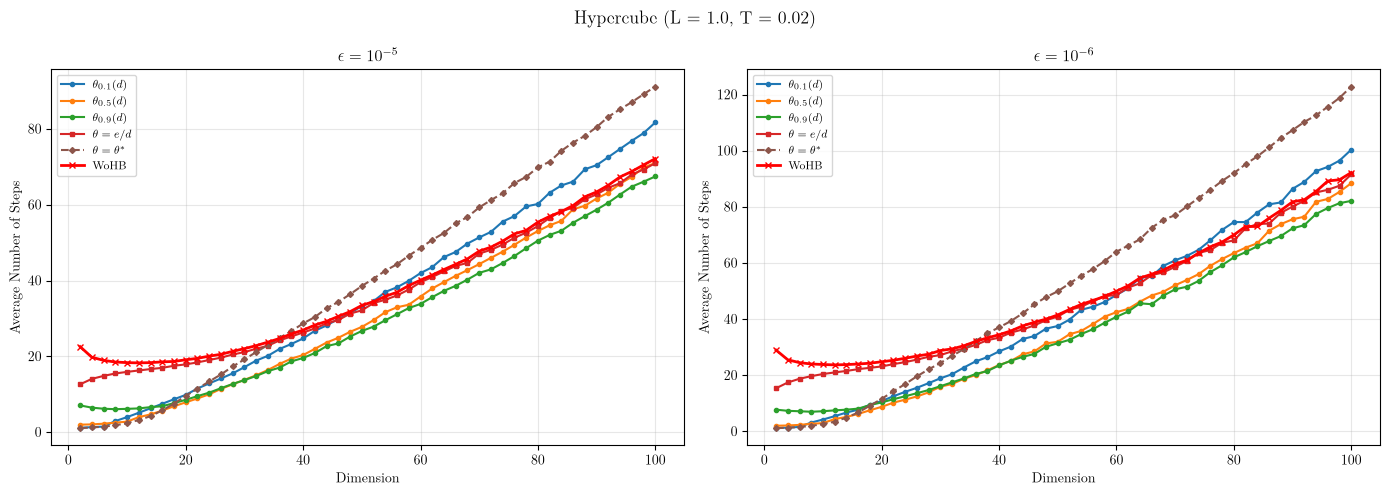

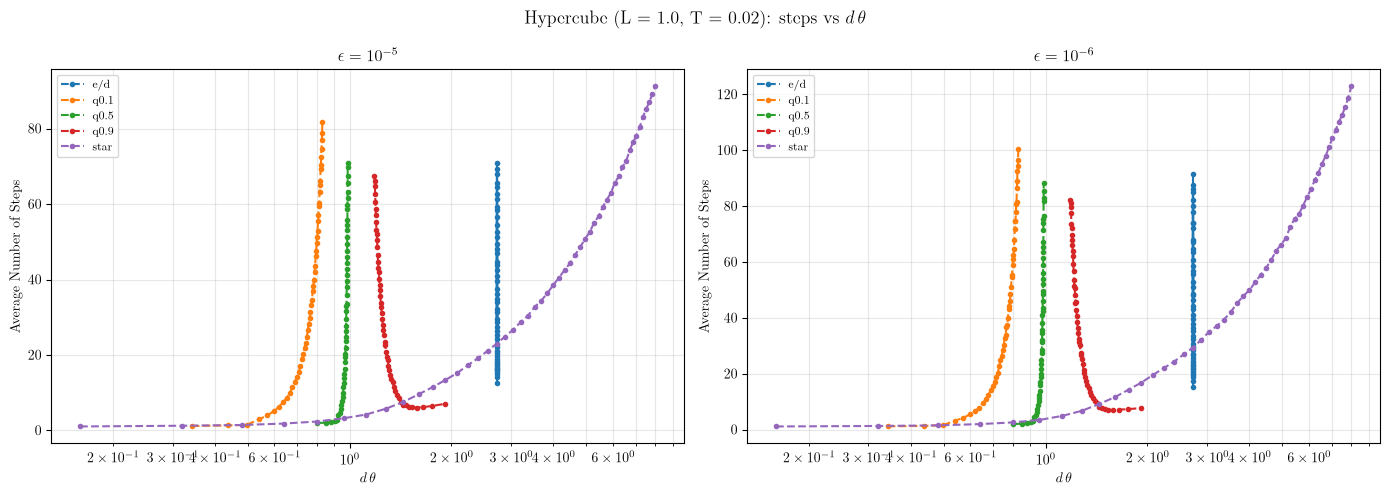

Saved: plot_Hypercube_L_1.0_T0.08.pdf


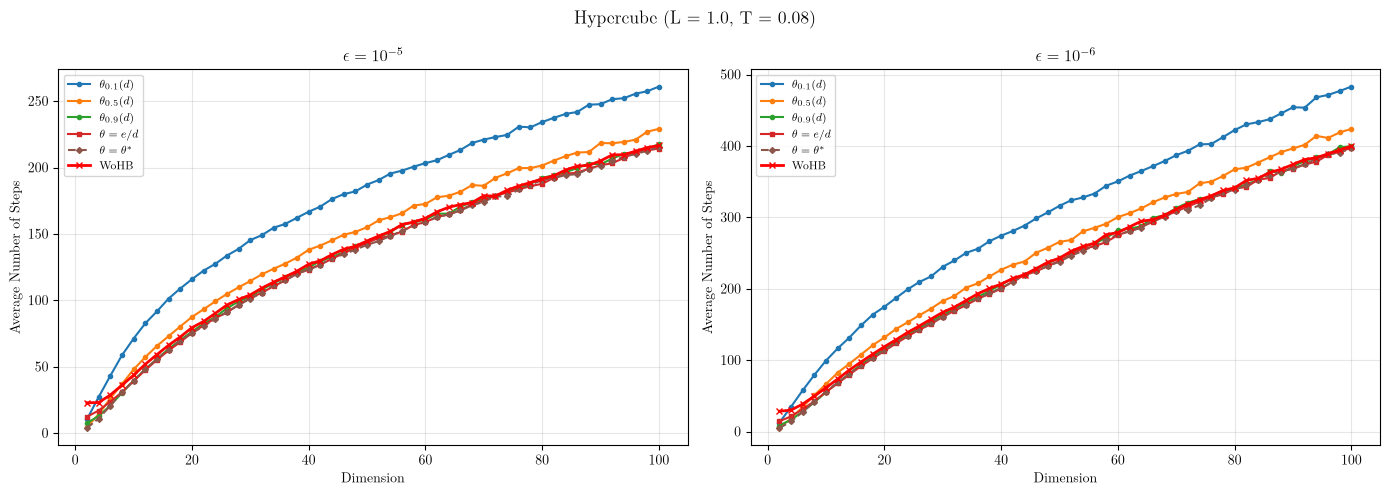

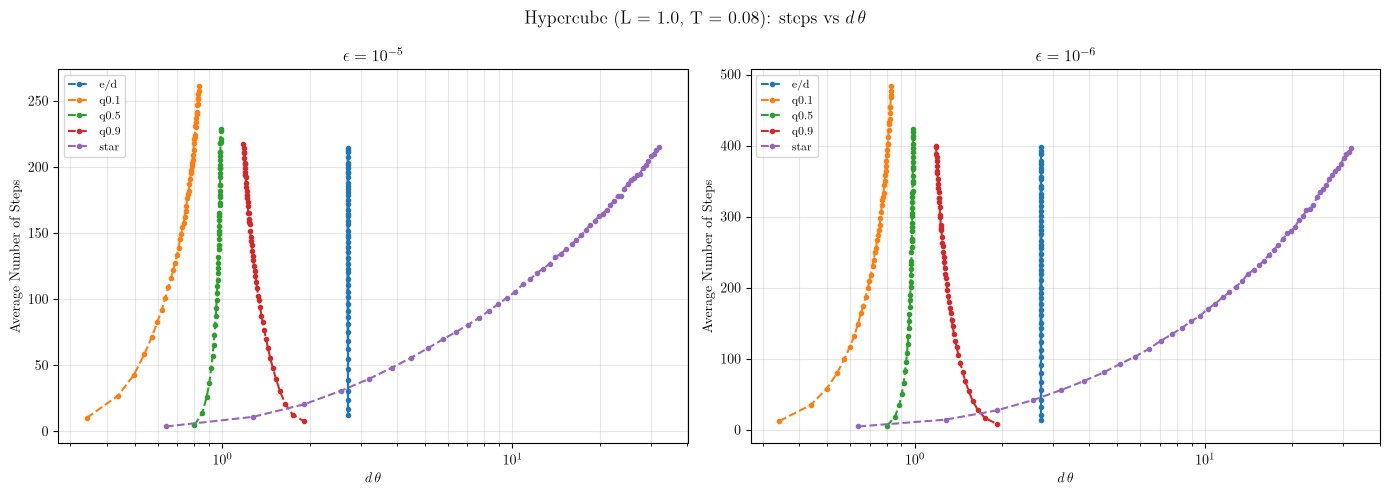

Saved: plot_Hypercube_L_1.0_T0.32.pdf


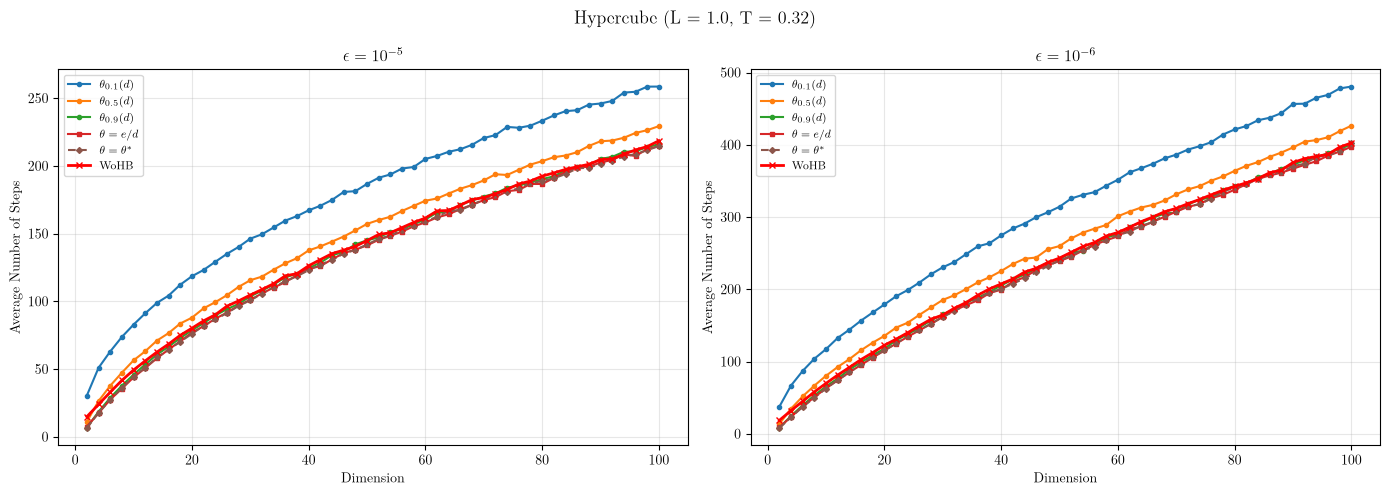

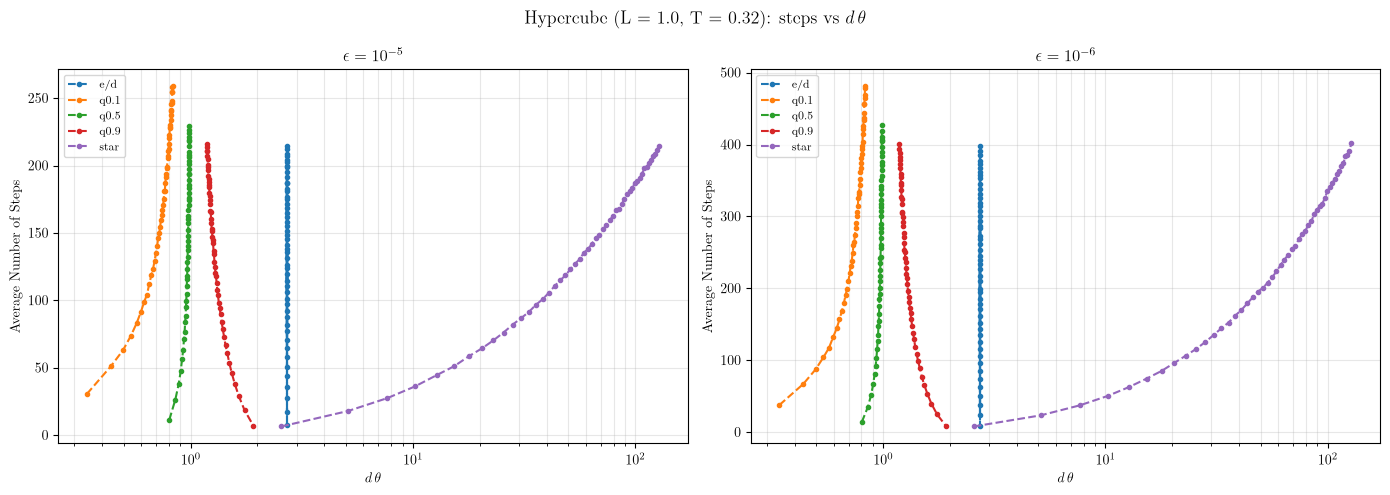

Saved: plot_Hypercube_L_1.0_T2.pdf


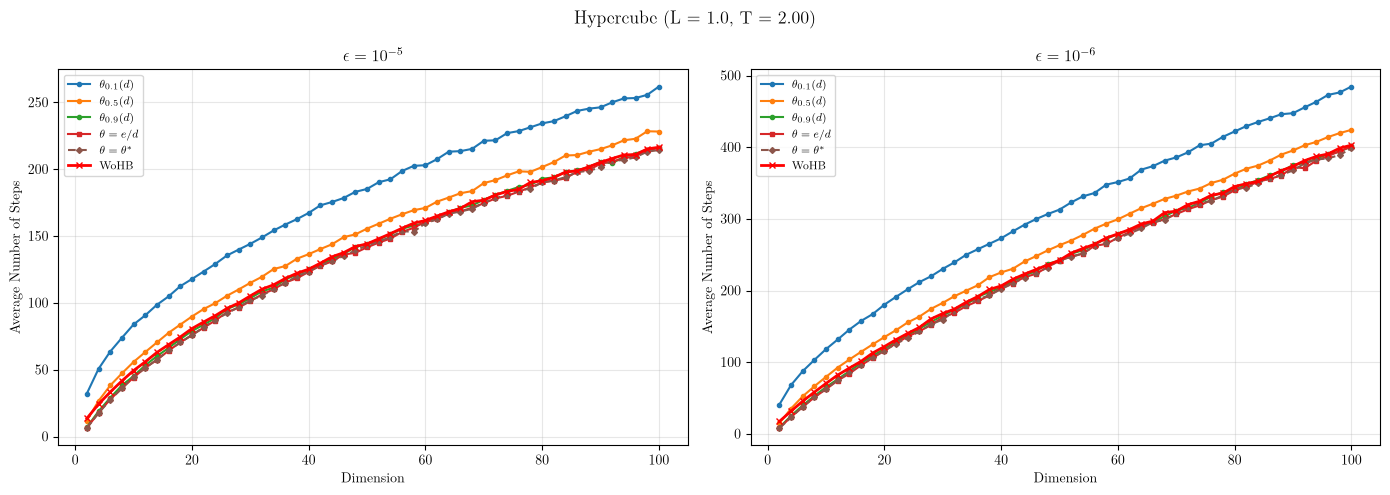

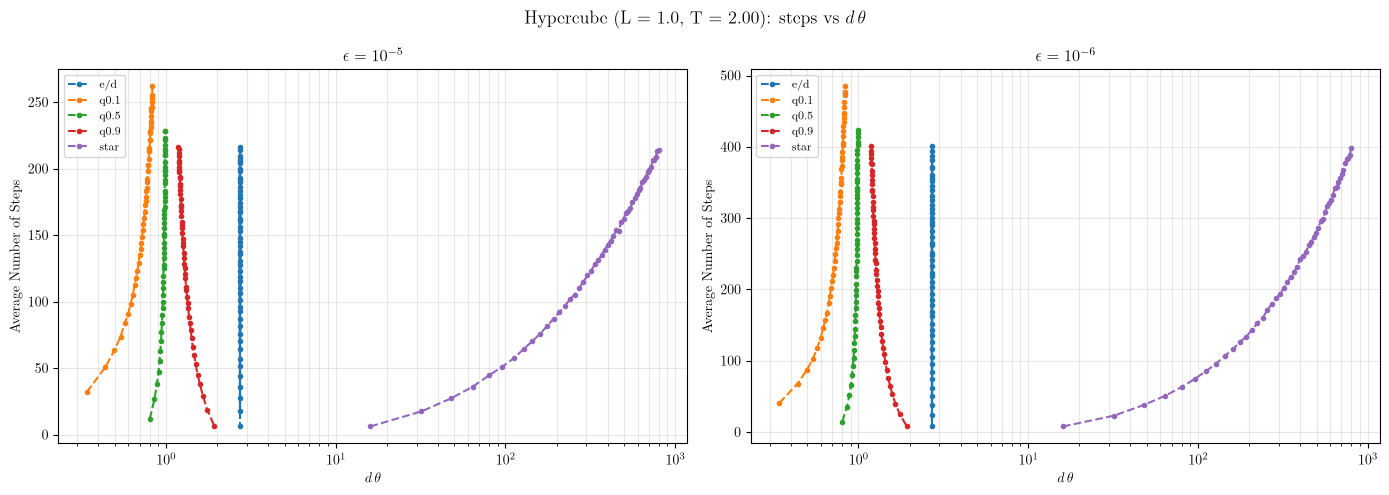

Saved: plot_Half-Sphere_R_1.0_T0.02.pdf


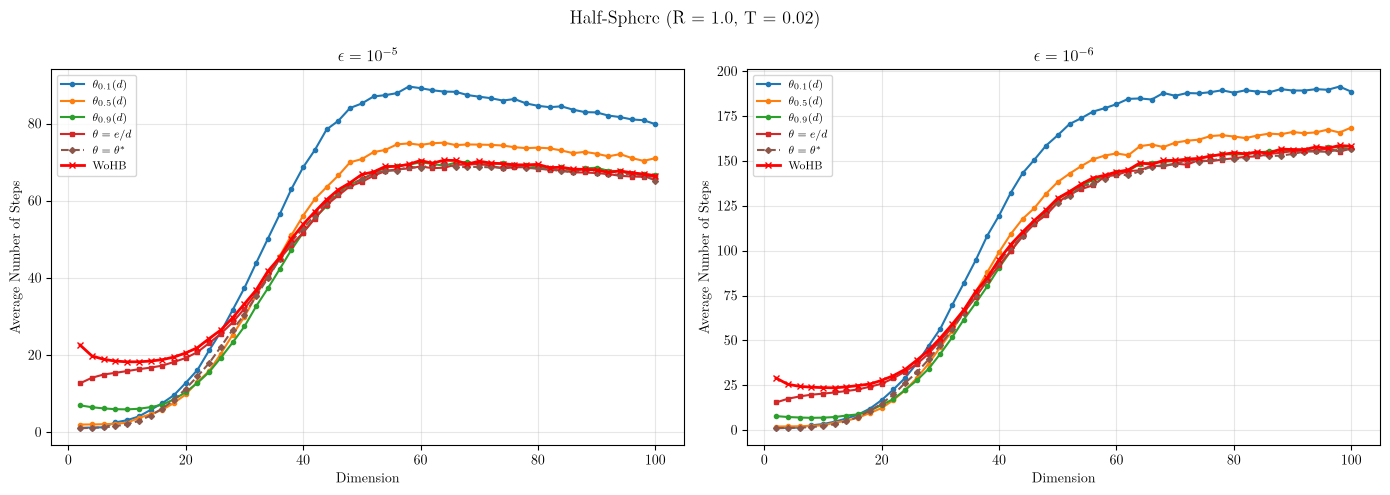

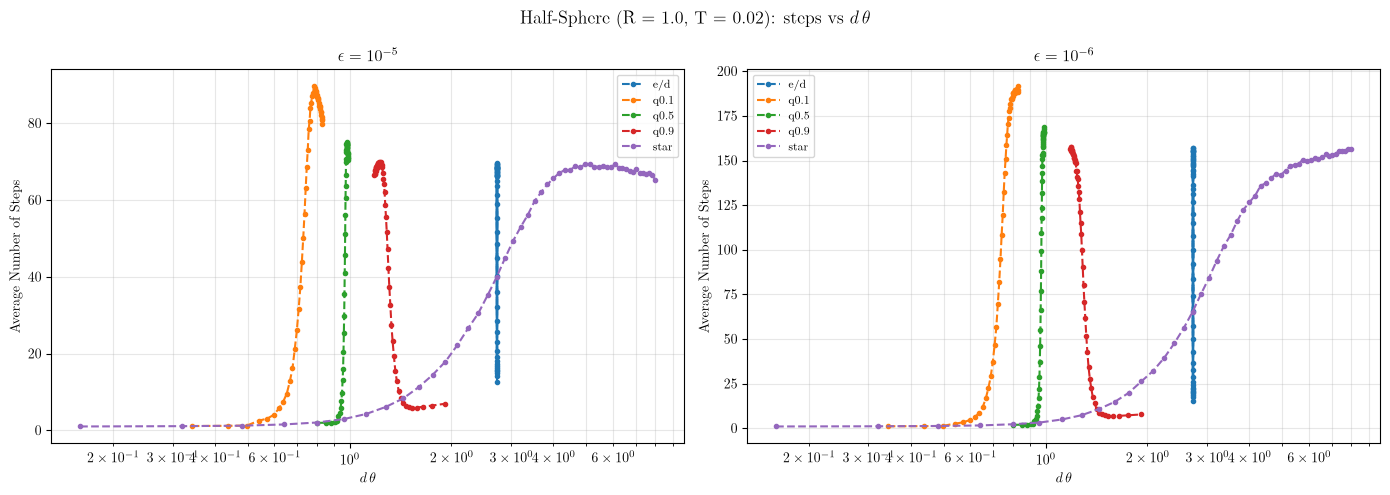

Saved: plot_Half-Sphere_R_1.0_T0.08.pdf


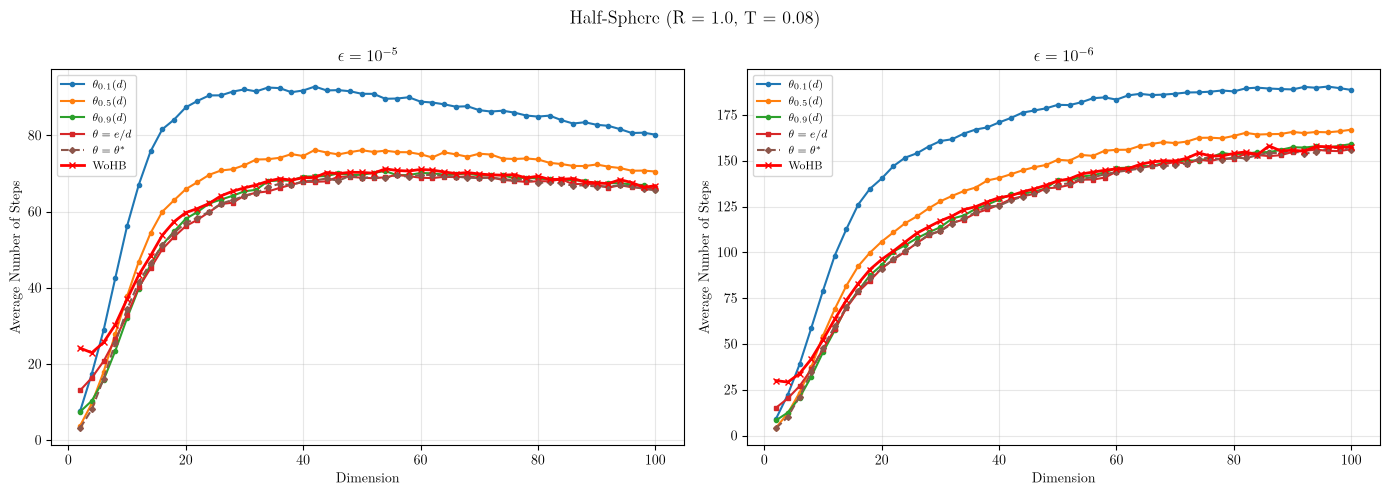

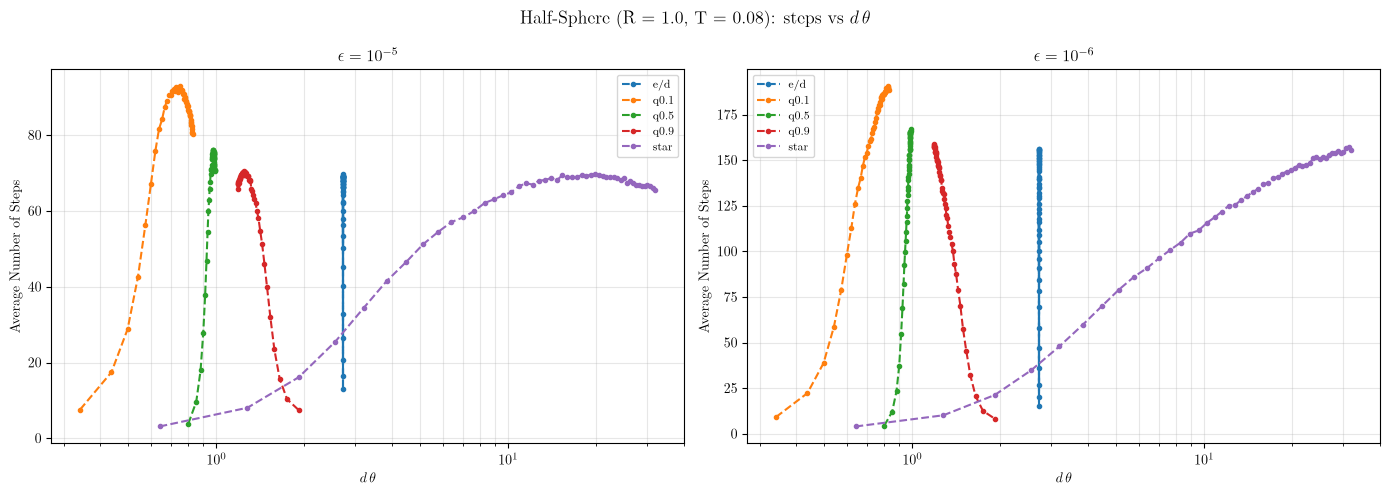

Saved: plot_Half-Sphere_R_1.0_T0.32.pdf


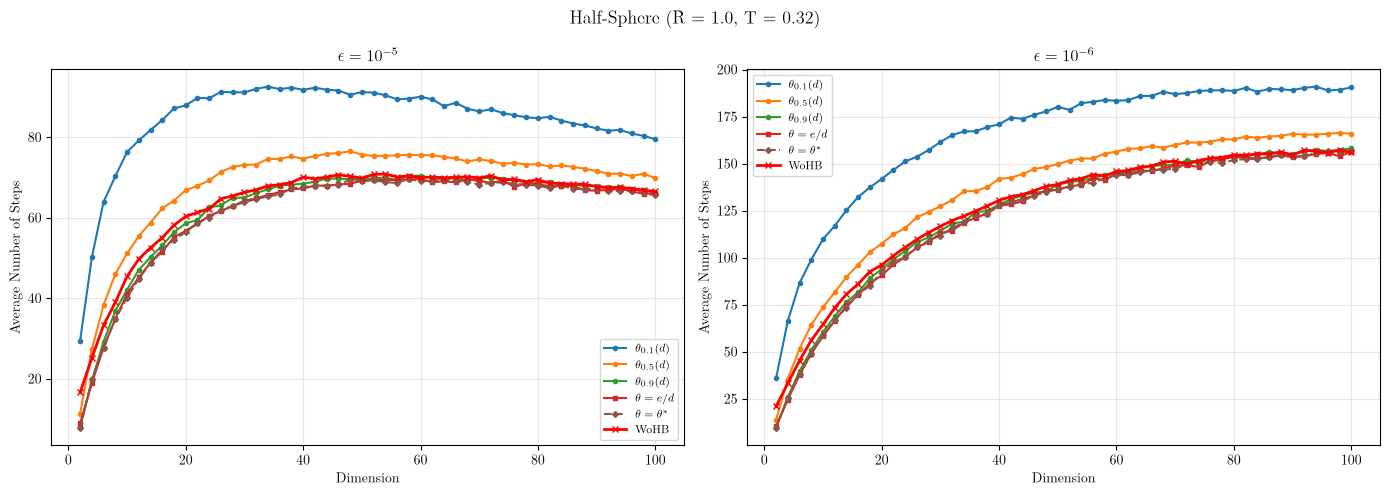

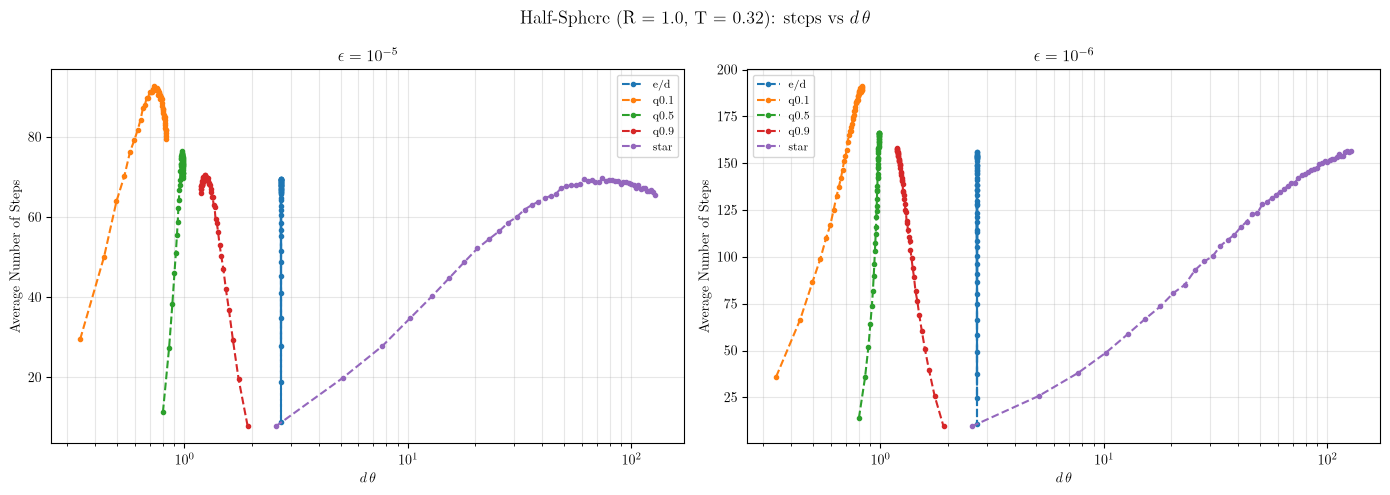

Saved: plot_Half-Sphere_R_1.0_T2.pdf


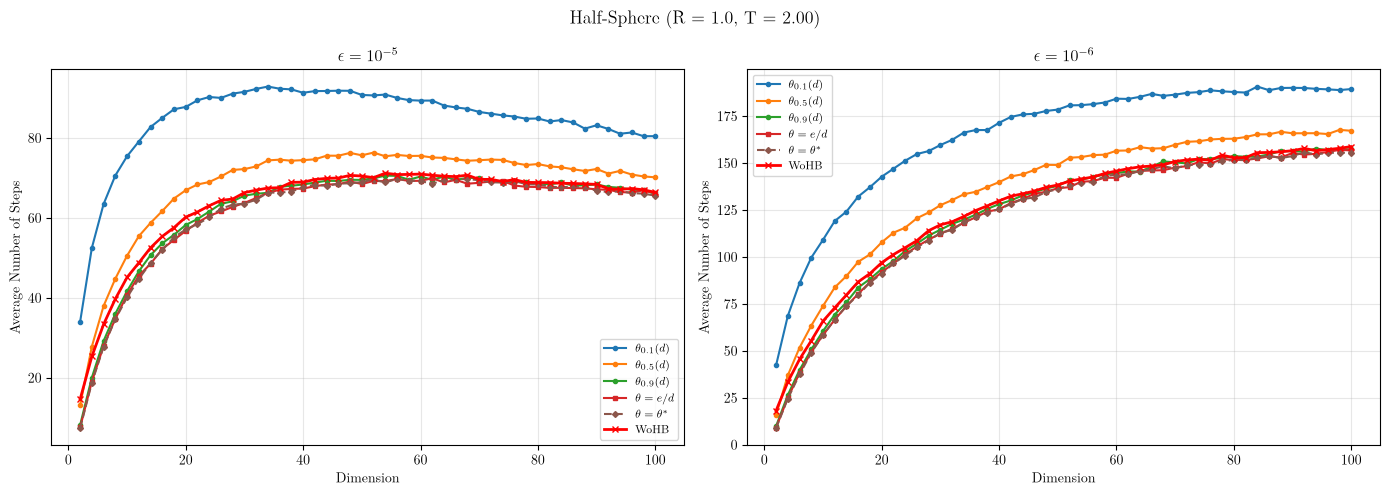

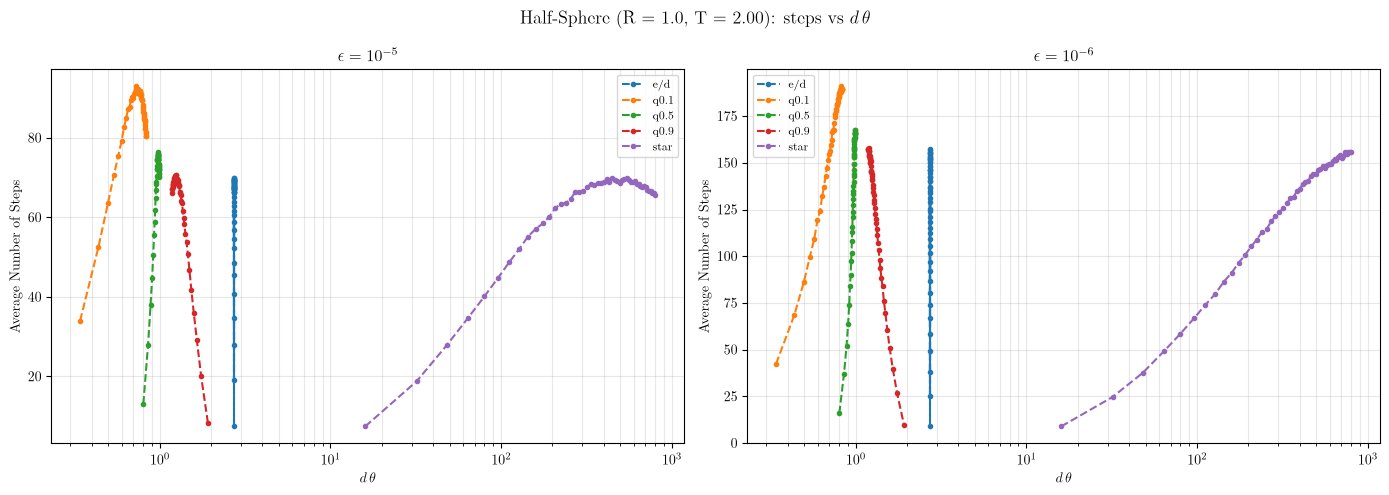

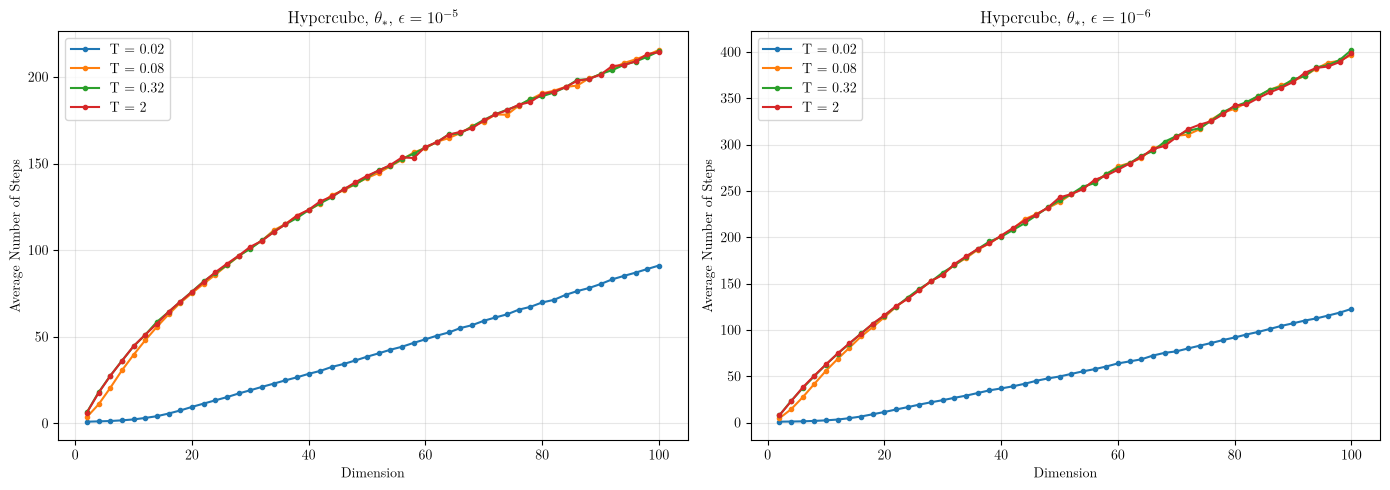

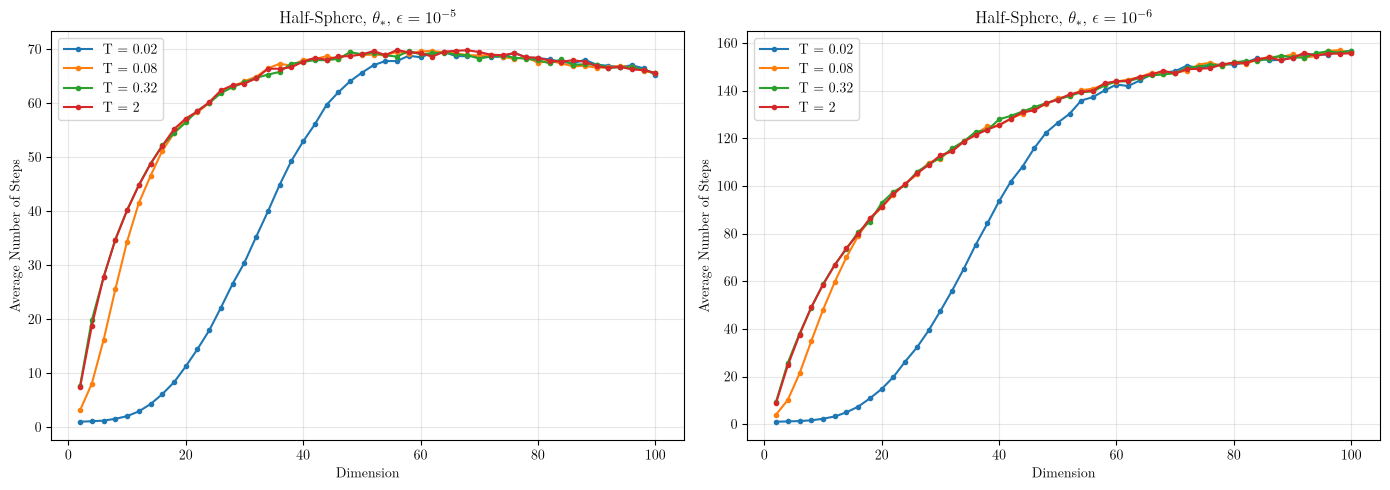

In [79]:
df_exp4 = pd.read_csv(RESULTS_DIR / 'woc_wohb_dim_scaling_results.csv')

colors = plt.cm.tab10.colors

df_exp4['d_theta'] = df_exp4['dimension'] * df_exp4['theta']

for cfg in domains_config:
    name = cfg['name']
    scale_values = [cfg['scale']]

    for scale in scale_values:
        scale_label = f'L = {scale}' if name == 'Hypercube' else f'R = {scale}'

        for T in cfg['T'][4]:

            fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
            fig.suptitle(f'{name} ({scale_label}, T = {T:.2f})', fontsize=13)

            position_labels = [f'q{p:g}' for p in THETA_QUANTILE_LEVELS]
            theta_pos_text = {f'q{p:g}': rf'$\theta_{{{p:g}}}(d)$' for p in THETA_QUANTILE_LEVELS}

            for ax, eps in zip(axes, cfg['epsilon_value']):

                for i, p in enumerate(position_labels):
                    subset_q = df_exp4[
                        (df_exp4['domain'] == name) &
                        (df_exp4['method'] == 'WoC') &
                        (df_exp4['theta_label'] == p) &
                        (df_exp4['scale'] == scale) &
                        np.isclose(df_exp4['epsilon'], eps) & 
                        np.isclose(df_exp4['T'], T)
                    ].sort_values('dimension')
                    if len(subset_q) > 0:
                        ax.plot(subset_q['dimension'], subset_q['mean_steps'], marker='o', markersize=3, label=theta_pos_text[p], color=colors[i])

                subset_e2d = df_exp4[
                    (df_exp4['domain'] == name) &
                    (df_exp4['method'] == 'WoC') &
                    (df_exp4['scale'] == scale) &
                    np.isclose(df_exp4['epsilon'], eps) &
                    np.isclose(df_exp4['T'], T) &
                    (df_exp4['theta_label'] == 'e/d')
                ].sort_values('dimension')

                if len(subset_e2d) > 0:
                    ax.plot(subset_e2d['dimension'], subset_e2d['mean_steps'], marker='s', markersize=3, label=r'$\theta = e/d$', color=colors[3])

                subset_large = df_exp4[
                    (df_exp4['domain'] == name) &
                    (df_exp4['method'] == 'WoC') &
                    (df_exp4['scale'] == scale) &
                    np.isclose(df_exp4['epsilon'], eps) &
                    np.isclose(df_exp4['T'], T) &
                    (df_exp4['theta_label'] == 'large')
                ].sort_values('dimension')

                if len(subset_large) > 0:
                    ax.plot(subset_large['dimension'], subset_large['mean_steps'], marker='^', markersize=3, label=rf'$\theta = {THETA_LARGE_FACTOR:g}\,\theta_{{0.9}}(d)$', color=colors[4])

                subset_star = df_exp4[
                    (df_exp4['domain'] == name) &
                    (df_exp4['method'] == 'WoC') &
                    (df_exp4['scale'] == scale) &
                    np.isclose(df_exp4['epsilon'], eps) &
                    np.isclose(df_exp4['T'], T) &
                    (df_exp4['theta_label'] == 'star')
                ].sort_values('dimension')

                if len(subset_star) > 0:
                    ax.plot(subset_star['dimension'], subset_star['mean_steps'], marker='D', markersize=3, linestyle='--', label=rf'$\theta = \theta^*$', color=colors[5])             

                subset_wohb = df_exp4[
                    (df_exp4['domain'] == name) &
                    (df_exp4['method'] == 'WoHB') &
                    (df_exp4['scale'] == scale) &
                    np.isclose(df_exp4['epsilon'], eps) &
                    np.isclose(df_exp4['T'], T)
                ].sort_values('dimension')

                if len(subset_wohb) > 0:
                    ax.plot(subset_wohb['dimension'], subset_wohb['mean_steps'], marker='x', markersize=4, color='red', linewidth=2, label=f'WoHB')

                ax.set_title(rf'$\epsilon = 10^{{{round(np.log10(eps))}}}$')
                ax.set_xlabel('Dimension')
                ax.set_ylabel('Average Number of Steps')
                #ax.set_yscale('log')
                ax.grid(alpha=0.3)
                ax.legend(fontsize=8)

            plt.tight_layout()
            clean_label = scale_label.replace(" ", "").replace("=", "_")
            filename = f'plot_{name}_{clean_label}_T{T:g}.pdf'

            save_fig(filename)
            print(f'Saved: {filename}')
            plt.show()

            fig2, axes2 = plt.subplots(1, 2, figsize=(14,5), sharey=False)
            fig2.suptitle(rf'{name} ({scale_label}, T = {T:.2f}): steps vs $d\, \theta$', fontsize=13)

            for ax2, eps in zip(axes2, cfg['epsilon_value']):
                sub = df_exp4[
                    (df_exp4['domain'] == name) &
                    (df_exp4['method'] == 'WoC') &
                    (df_exp4['scale'] == scale) &
                    np.isclose(df_exp4['epsilon'], eps) &
                    np.isclose(df_exp4['T'], T)
                ]

                for lab, g_ in sub.groupby('theta_label'):
                    g_ = g_.sort_values('d_theta')
                    ax2.plot(g_['d_theta'], g_['mean_steps'], marker='o', markersize=3,
                             linestyle='--', label=lab)

                ax2.set_xscale('log')
                ax2.set_xlabel(r'$d\, \theta$')
                ax2.set_ylabel('Average Number of Steps')
                ax2.set_title(rf'$\epsilon = 10^{{{round(np.log10(eps))}}}$')
                ax2.grid(alpha=0.3, which='both')
                ax2.legend(fontsize=8)

            plt.tight_layout()
            save_fig(f'plot_{name}_{clean_label}_T{T:g}_dtheta.pdf')
            plt.show()

for cfg in domains_config:
    name = cfg['name']
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, eps in zip(axes, cfg['epsilon_value']):
        for T in cfg['T'][4]:
            s = df_exp4[(df_exp4['domain'] == name) & (df_exp4['method'] == 'WoC') &
                        (df_exp4['theta_label'] == 'star') &
                        np.isclose(df_exp4['epsilon'], eps) & np.isclose(df_exp4['T'], T)].sort_values('dimension')
            ax.plot(s['dimension'], s['mean_steps'], marker='o', markersize=3, label=f'T = {T:g}')
        ax.set_xlabel('Dimension')
        ax.set_ylabel('Average Number of Steps')
        ax.set_title(rf'{name}, $\theta_*$, $\epsilon = 10^{{{round(np.log10(eps))}}}$')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [29]:
df_exp4 = pd.read_csv(RESULTS_DIR / 'woc_wohb_dim_scaling_results.csv')

# ── Is WoC-at-theta_0.1 aligned with WoHB because both are boundary-dominated? ──
name  = 'Half-Sphere'
scale = domains_config[1]['scale']   # R = 1.0

for eps in domains_config[1]['epsilon_value']:
    print(f'\n=== {name} | eps = {eps:.0e} ===')
    print(f'{"dim":>4} {"theta_0.1":>9} {"WoC_frac":>9} {"WoC_steps":>10} '
          f'{"WoHB_frac":>10} {"WoHB_steps":>11} {"step_ratio":>11}')

    dims = np.sort(df_exp4[
        (df_exp4['domain'] == name) & (df_exp4['method'] == 'WoC') &
        (df_exp4['scale'] == scale) & (df_exp4['epsilon'] == eps)
    ]['dimension'].unique())

    for dim in dims:
        woc_dim = df_exp4[
            (df_exp4['theta_label'] == 'q0.1') &
            (df_exp4['domain'] == name) & (df_exp4['method'] == 'WoC') &
            (df_exp4['scale'] == scale) & (df_exp4['epsilon'] == eps) &
            (df_exp4['dimension'] == dim)
        ]
        if len(woc_dim) == 0:
            continue
        # theta_0.1 = smallest theta actually simulated at this dimension
        row_min = woc_dim.loc[woc_dim['theta'].idxmin()]

        wohb_dim = df_exp4[
            (df_exp4['domain'] == name) & (df_exp4['method'] == 'WoHB') &
            (df_exp4['scale'] == scale) & (df_exp4['epsilon'] == eps) &
            (df_exp4['dimension'] == dim)
        ]
        if len(wohb_dim) == 0:
            continue
        wohb_row = wohb_dim.iloc[0]

        ratio = row_min['mean_steps'] / wohb_row['mean_steps']
        print(f'{dim:>4} {row_min["theta"]:>9.4f} {row_min["space_exit_proportion"]:>9.3f} '
              f'{row_min["mean_steps"]:>10.1f} {wohb_row["space_exit_proportion"]:>10.3f} '
              f'{wohb_row["mean_steps"]:>11.1f} {ratio:>11.2f}')


=== Half-Sphere | eps = 1e-03 ===
 dim theta_0.1  WoC_frac  WoC_steps  WoHB_frac  WoHB_steps  step_ratio
   2    0.1709     1.000       18.1      1.000         7.2        2.53
   4    0.1094     1.000       21.0      1.000        11.0        1.91
   8    0.0674     1.000       23.6      1.000        12.2        1.93


## Experiment 5: effect of the time tolerance $\epsilon_0$ (bounded vs unbounded)
$\epsilon_1=\sqrt{\epsilon d/e}$ is held fixed and $\epsilon_0$ is swept (`tol_time_values`). Each $(T,\theta)$ is run in the bounded domains and, for comparison, with the spatial boundary switched off (`use_spatial_boundary=False`, i.e. $\mathbb{R}^d$: the walk then only stops at a terminal-face exit or when the remaining time is at most $\epsilon_0$). Runs that exceed `MAX_STEPS_exp5` steps are recorded as NaN. The estimate of the unbounded runs has no meaning (no boundary condition is applied); only their step counts do.

In [30]:
# ── EXPERIMENT 5: SIMULATION ──
results_exp5 = []
done_unbounded = set()   # the unbounded walk ignores the domain and eps_1: run it once per (T, theta)
exp5_time = time.time()

for cfg in domains_config:
    name, domain, x0 = cfg['name'], cfg['domain'], cfg['x0']
    f, g, scale = cfg['f'], cfg['g'], cfg['scale']
    print(f'\n--- {name} ---')

    for eps in cfg['epsilon_value']:
        tol_space = tol_space_for(eps, DIM)

        for T in cfg['T'][5]:
            for theta in cfg['theta_values']:
                print(f'    eps={eps:.0e}, T={T}, theta={theta:.4f}…')

                for bounded in (True, False):
                    if not bounded:
                        key = (T, float(theta))
                        if key in done_unbounded:
                            continue
                        done_unbounded.add(key)

                    WOC_theta = WalkOnCylinders(DIM, domain, float(theta), N_ZEROS, INV_R, INV_T, _eps=_eps,
                                                max_steps=MAX_STEPS_exp5, N_cutoff=N_cutoff,
                                                seed=seed_for('exp5', name, eps, T, theta, bounded),
                                                use_spatial_boundary=bounded)

                    for tol_time in tol_time_values:
                        try:
                            woc_vals, woc_steps, woc_flags = heat_mc_solution_vector_WOC(
                                WOC_theta, T, x0, f, g, DIM, scale, N_PATHS_exp5, tol_space, tol_time)
                            woc_steps, woc_vals = np.asarray(woc_steps), np.asarray(woc_vals)
                            stats = {'mean_steps': woc_steps.mean(),
                                     'p99_steps': np.percentile(woc_steps, 99),
                                     'max_steps': woc_steps.max(),
                                     'space_exit_proportion': np.mean(woc_flags),
                                     'estimate_mean': woc_vals.mean(),
                                     'estimate_se': woc_vals.std(ddof=1) / np.sqrt(N_PATHS_exp5)}
                        except RuntimeError:   # path exceeded MAX_STEPS_exp5
                            stats = dict.fromkeys(['mean_steps', 'p99_steps', 'max_steps',
                                                   'space_exit_proportion', 'estimate_mean', 'estimate_se'], np.nan)

                        results_exp5.append({'domain': name if bounded else 'Unbounded',
                                             'epsilon': eps if bounded else np.nan,
                                             'T': T, 'theta': theta, 'bounded': bounded,
                                             'tol_time': tol_time, **stats})

df_exp5 = pd.DataFrame(results_exp5)
df_exp5.to_csv(RESULTS_DIR / 'woc_time_tolerance_results.csv', index=False)
print(f'\nExperiment 5 completed in {time.time() - exp5_time:.2f} seconds.')


--- Hypercube ---
    eps=1e-03, T=2.0, theta=0.1322…
    eps=1e-03, T=2.0, theta=0.2776…
    eps=1e-03, T=2.0, theta=0.6070…
    eps=1e-03, T=2.0, theta=0.9061…
    eps=1e-03, T=8.0, theta=0.1322…
    eps=1e-03, T=8.0, theta=0.2776…
    eps=1e-03, T=8.0, theta=0.6070…
    eps=1e-03, T=8.0, theta=0.9061…

--- Half-Sphere ---
    eps=1e-03, T=0.02, theta=0.1322…
    eps=1e-03, T=0.02, theta=0.2776…
    eps=1e-03, T=0.02, theta=0.6070…
    eps=1e-03, T=0.02, theta=0.9061…
    eps=1e-03, T=2.0, theta=0.1322…
    eps=1e-03, T=2.0, theta=0.2776…
    eps=1e-03, T=2.0, theta=0.6070…
    eps=1e-03, T=2.0, theta=0.9061…

Experiment 5 completed in 1.37 seconds.


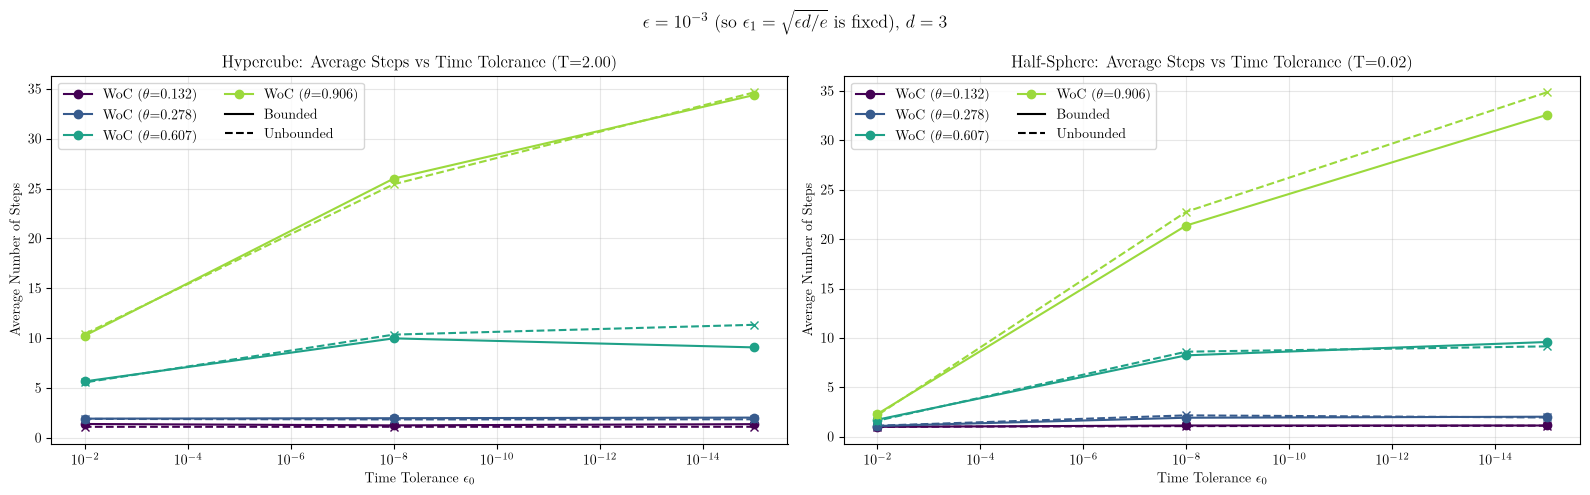

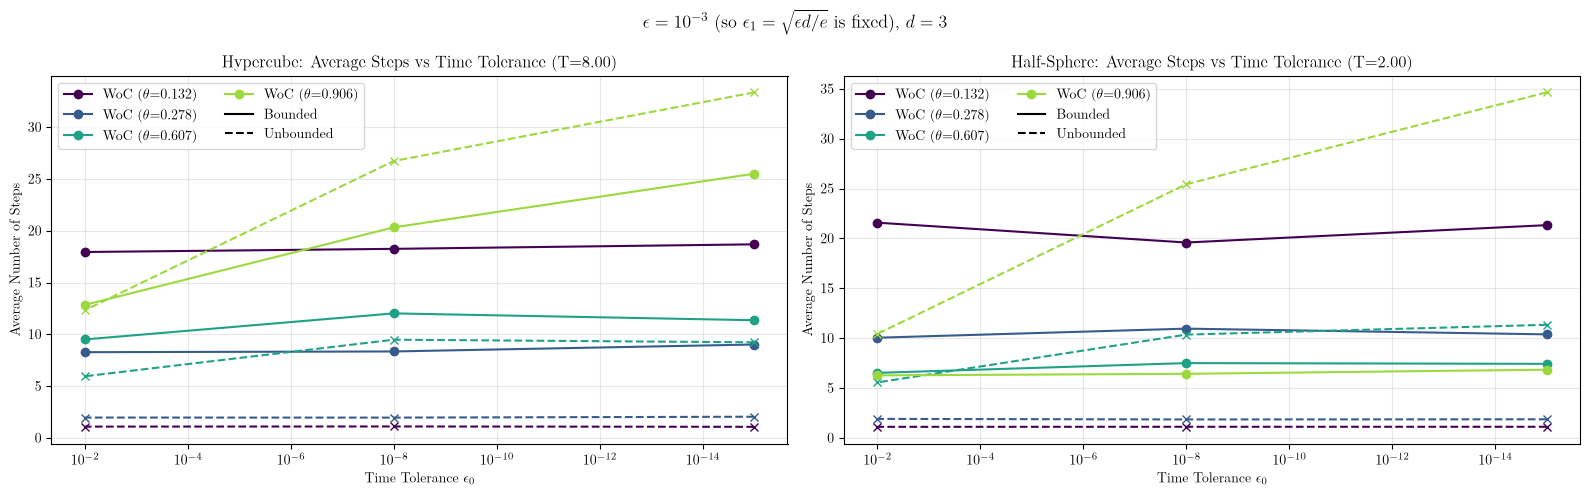

In [31]:
# ── EXPERIMENT 5: PLOTTING ──
df_exp5 = pd.read_csv(RESULTS_DIR / 'woc_time_tolerance_results.csv')

# One figure per (horizon, epsilon), hypercube and half-sphere side by side as in Experiments 2 and 3.
# Solid: bounded domain.  Dashed: unbounded (spatial boundary off; depends only on T and theta).
for k in range(len(domains_config[0]['T'][5])):
    for eps in domains_config[0]['epsilon_value']:
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))

        for ax, cfg in zip(axes, domains_config):
            name = cfg['name']
            T = cfg['T'][5][k]
            theta_plot = list(cfg['theta_values_plot'])
            theta_colors = {theta: c for theta, c in zip(theta_plot, plt.cm.viridis(np.linspace(0.0, 0.85, len(theta_plot))))}

            for theta in theta_plot:
                same_theta = np.isclose(df_exp5['theta'], theta)
                b = df_exp5[(df_exp5['domain'] == name) & np.isclose(df_exp5['epsilon'], eps) & np.isclose(df_exp5['T'], T) & same_theta].sort_values('tol_time')
                u = df_exp5[(df_exp5['domain'] == 'Unbounded') & np.isclose(df_exp5['T'], T) & same_theta].sort_values('tol_time')
                ax.plot(b['tol_time'], b['mean_steps'], label=rf'WoC ($\theta$={theta:.3f})', marker='o', color=theta_colors[theta])
                ax.plot(u['tol_time'], u['mean_steps'], linestyle='--', marker='x', color=theta_colors[theta])

            ax.plot([], [], color='black', linestyle='-', label='Bounded')
            ax.plot([], [], color='black', linestyle='--', label='Unbounded')
            ax.set_xscale('log')
            ax.invert_xaxis()   # tolerance gets tighter to the right
            ax.set_xlabel(r'Time Tolerance $\epsilon_0$')
            ax.set_ylabel('Average Number of Steps')
            ax.set_title(f'{name}: Average Steps vs Time Tolerance (T={T:.2f})')
            ax.legend(ncol=2)
            ax.grid(alpha=0.3, which='both')

        fig.suptitle(rf'$\epsilon = 10^{{{round(np.log10(eps))}}}$ (so $\epsilon_1 = \sqrt{{\epsilon d/e}}$ is fixed), $d = {DIM}$', fontsize=13)
        plt.tight_layout()
        save_fig(f'experiment5_avg_steps_vs_time_tolerance_eps{eps:.0e}_horizon{k + 1}.pdf')
        plt.show()

In [81]:
from scipy.stats import norm

def bachelier_call(s, K, T, dim):
    # The basket (mean of dim independent Brownian motions, generator is 1/2 laplacian) is N(s, T/dim) at time T
    sd = np.sqrt(T / dim)
    d = (s - K) / sd
    return sd * norm.pdf(d) + (s - K) * norm.cdf(d)

def basket_call_stats(x_T, K_values):
    # Price and 95% CI half-width at every strike, all from same Terminal points
    basket = x_T.mean(axis=1)  # mean across dimensions
    pay = np.maximum(basket[:, None] - np.asarray(K_values)[None, :], 0.0)  # shape (N_PATHS, len(K_values))
    return pay.mean(axis=0), 1.96 * pay.std(axis=0, ddof=1) / np.sqrt(len(basket))

if RECOMPUTE.get(6, True) or not (RESULTS_DIR / 'exp6_results.csv').exists():
    exp6_time = time.time()
    s_exp6 = float(np.mean(x0_exp6))
    exact_exp6 = bachelier_call(s_exp6, K_exp6, T_exp6, DIM_exp6)
    # The walks run on R^d (use_spatial_boundary=False); the domain is required by the classes but not used
    dummy_domain = BoxDomain(a=x0_exp6 - 1.0, b=x0_exp6 + 1.0)
    rows = []

    # WoC: on R^d each cylinder reaches the horizon, so a terminal exit lands exactly at T; tol_time = 0 keeps it exact
    for theta in get_theta_quantiles(DIM_exp6, THETA_QUANTILE_LEVELS):
        print(f'WoC with theta = {theta:.4f}…')
        WOC_theta = WalkOnCylinders(DIM_exp6, dummy_domain, float(theta), N_ZEROS, INV_R, INV_T, _eps=_eps,
                                    N_cutoff=N_cutoff, seed=seed_for('exp6', 'woc', theta), use_spatial_boundary=False)
        x_T = np.empty((N_PATHS_exp6, DIM_exp6))
        steps = np.empty(N_PATHS_exp6)
        for i in range(N_PATHS_exp6):
            res = WOC_theta.simulate_path(T_exp6, x0_exp6, tol_space=0.0, tol_time=0.0)
            x_T[i], steps[i] = res.x_final, res.num_steps
        price, ci = basket_call_stats(x_T, K_exp6)
        rows += [{'method': 'WoC', 'theta': float(theta), 'K': K, 'price': p, 'ci': c, 'exact': e, 'mean_steps': steps.mean()}
                 for K, p, c, e in zip(K_exp6, price, ci, exact_exp6)]

    # WoHB: alpha = remaining time on R^d; the walk stops when the remaining time is <= eps_exp6
    print('WoHB…')
    WOHB = WalkOnHeatBalls(DIM_exp6, dummy_domain, seed=seed_for('exp6', 'wohb'), use_spatial_boundary=False)
    x_T = np.empty((N_PATHS_exp6, DIM_exp6))
    steps = np.empty(N_PATHS_exp6)
    for i in range(N_PATHS_exp6):
        _, x_T[i], steps[i] = WOHB.one_sample(T_exp6, x0_exp6, eps_exp6)
    price, ci = basket_call_stats(x_T, K_exp6)
    rows += [{'method': 'WoHB', 'theta': np.nan, 'K': K, 'price': p, 'ci': c, 'exact': e, 'mean_steps': steps.mean()}
             for K, p, c, e in zip(K_exp6, price, ci, exact_exp6)]

    pd.DataFrame(rows).to_csv(RESULTS_DIR / 'exp6_results.csv', index=False)
    print(f'Experiment 6 done in {time.time() - exp6_time:.1f} s')

WoC with theta = 0.1322…
WoC with theta = 0.2776…
WoC with theta = 0.6070…
WoHB…
Experiment 6 done in 16.6 s


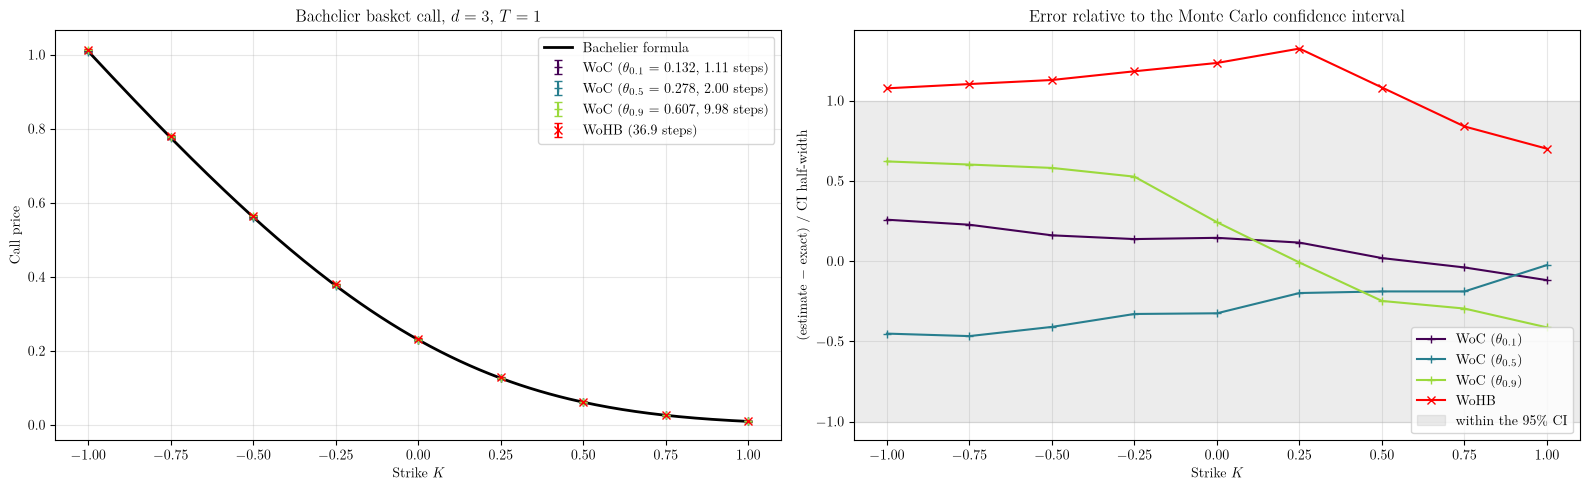

In [82]:
# ── EXPERIMENT 6: PLOTTING ──────────────────────────────────────────────────────
df_exp6 = pd.read_csv(RESULTS_DIR / 'exp6_results.csv')
woc6 = df_exp6[df_exp6['method'] == 'WoC']
wohb6 = df_exp6[df_exp6['method'] == 'WoHB']
theta_list6 = sorted(woc6['theta'].unique())
theta_colors6 = dict(zip(theta_list6, plt.cm.viridis(np.linspace(0.0, 0.85, len(theta_list6)))))
labels6 = {th: rf'$\theta_{{{p}}}$' for p, th in zip(THETA_QUANTILE_LEVELS, theta_list6)}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
K_fine = np.linspace(K_exp6.min(), K_exp6.max(), 200)
axes[0].plot(K_fine, bachelier_call(float(np.mean(x0_exp6)), K_fine, T_exp6, DIM_exp6), color='black', linewidth=2, label='Bachelier formula')
for th in theta_list6:
    sub = woc6[np.isclose(woc6['theta'], th)].sort_values('K')
    axes[0].errorbar(sub['K'], sub['price'], yerr=sub['ci'], fmt='+', capsize=3, color=theta_colors6[th],
                     label=rf'WoC ({labels6[th]} = {th:.3f}, {sub["mean_steps"].iloc[0]:.2f} steps)')
    axes[1].plot(sub['K'], (sub['price'] - sub['exact']) / sub['ci'], marker='+', color=theta_colors6[th], label=rf'WoC ({labels6[th]})')
sub = wohb6.sort_values('K')
axes[0].errorbar(sub['K'], sub['price'], yerr=sub['ci'], fmt='x', capsize=3, color='red',
                 label=f'WoHB ({sub["mean_steps"].iloc[0]:.1f} steps)')
axes[1].plot(sub['K'], (sub['price'] - sub['exact']) / sub['ci'], marker='x', color='red', label='WoHB')
axes[1].axhspan(-1, 1, color='gray', alpha=0.15, label=f'within the 95{PCT} CI')

axes[0].set_xlabel('Strike $K$'); axes[0].set_ylabel('Call price')
axes[0].set_title(rf'Bachelier basket call, $d={DIM_exp6}$, $T={T_exp6:g}$')
axes[1].set_xlabel('Strike $K$'); axes[1].set_ylabel(r'(estimate $-$ exact) / CI half-width')
axes[1].set_title('Error relative to the Monte Carlo confidence interval')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('experiment6_bachelier_basket_call.pdf')
plt.show()